# Fenchel–Young duality gaps — companion experiments

Companion notebook to the two-paper series by **Pierre-Cyril Aubin-Frankowski
and Yohann De Castro (2026)**:

1. **Paper I** — *Fenchel–Young Duality Gaps: Certified Early Stopping for
   Regularized Inverse Problems* (`main_FY_gap.tex`).
2. **Paper II** — *Localization and Exact Support Recovery for the
   Generalized Beurling–Lasso* (`main_GBL_NDSC.tex`).

The notebook reproduces **all four publication figures** of the two papers,
together with the short in-text verification checks quoted in their
experiment sections:

| Part | Paper | Figure | File | Where |
|---|---|---|---|---|
| I | Paper I | Fig 1 (`fig:lion_muon_delta`) | `fig_lion_muon_delta.pdf` | intro + §5.3 |
| I | Paper I | Fig 2 (`fig:certificate_evolution`) | `fig_certificate_evolution.pdf` | §5.1 |
| I | Paper I | Fig 3 (`fig:fy_decomposition_synthetic`) | `fig_fy_decomposition_synthetic.pdf` | §5.2 |
| II | Paper II | Fig 3 (`fig:logistic_well_spec`) | `fig_logistic_well_spec.pdf` | §5.1 |

All shared utilities live in the `gbl/` package next to this notebook
(`particles.py`, `problems.py`, `optimizers.py`, `fy.py`, `utils.py`,
`plotting.py`). The notebook runs end-to-end on its own; figures are saved
into `./figs/` by default (see the setup cell to redirect them, e.g. into a
LaTeX project).

## C0 — Setup and imports

In [1]:
from __future__ import annotations

import time
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import torch

In [2]:
# Local package (next to this notebook).
import sys
sys.path.insert(0, str(Path(__file__).parent.resolve())) if "__file__" in dir() else None  # type: ignore

import gbl
from gbl import (
    ConicOptimizer,
    FYTracker,
    GaussianBlasso,
    LogisticGaussianBlasso,
    MirrorRetraction,
    Particles,
    cluster_recovery_error,
    initialize_gaussian_particles,
    mirror_alignment_check,
    print_mirror_alignment,
    sample_logistic_gbl,
    synth_1d_problem,
)
from gbl import plotting as gplt

torch.manual_seed(314)
np.random.seed(314)

In [3]:
# Sanity check: the public API the experiments rely on.
print("gbl module:", gbl)
for name in ("GaussianBlasso", "LogisticGaussianBlasso", "ConicOptimizer",
             "MirrorRetraction", "Particles", "FYTracker", "synth_1d_problem",
             "sample_logistic_gbl", "initialize_gaussian_particles",
             "cluster_recovery_error", "mirror_alignment_check"):
    obj = getattr(gbl, name)
    kind = "class" if isinstance(obj, type) else "callable"
    print(f"  {name:30s}  ({kind})")

gbl module: <module 'gbl' from '/Users/yohann/Library/CloudStorage/Dropbox/0_Yohann/7_Code/2026_FYL_gap/fenchel-young-gaps/gbl/__init__.py'>
  GaussianBlasso                  (class)
  LogisticGaussianBlasso          (class)
  ConicOptimizer                  (class)
  MirrorRetraction                (class)
  Particles                       (class)
  FYTracker                       (class)
  synth_1d_problem                (callable)
  sample_logistic_gbl             (callable)
  initialize_gaussian_particles   (callable)
  cluster_recovery_error          (callable)
  mirror_alignment_check          (callable)


In [4]:
# Output directory for the publication figures. Defaults to ./figs next to the
# notebook; set the environment variable FYG_FIGS_DIR to redirect (e.g. into a
# LaTeX project's figs/ directory).
import os as _os
FIGS_DIR = Path(_os.environ.get("FYG_FIGS_DIR", Path.cwd() / "figs"))
FIGS_DIR.mkdir(parents=True, exist_ok=True)
print(f"Figures will be saved to: {FIGS_DIR}")

# Publication style — only locally; restored at the end of the notebook.
_prev_rc = mpl.rcParams.copy()
mpl.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "legend.fontsize": 9,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "pdf.fonttype": 42,           # editable text in vector PDF
    "ps.fonttype": 42,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.05,
})

Figures will be saved to: /Users/yohann/Library/CloudStorage/Dropbox/0_Yohann/7_Code/2026_FYL_gap/fenchel-young-gaps/figs


## Methods — the Fenchel–Young duality-gap diagnostic (Paper I §2 + Remark `rem:dual_rescaling`)

Every experiment reads the *honest* duality gap of **Theorem 1**
(`thm:dual_gap`, Paper I §2 `sec:controlled_gaps`) evaluated at the **rescaled**
Mirror-Alignment dual $\tilde h_k = c_k\,\nabla F(\Phi\mu_k)$, with
$c_k = \min\bigl(1,\,\lambda/\|\Phi^\star\nabla F(\Phi\mu_k)\|_\infty\bigr)
 = \min(1, 1/\|\eta_k\|_\infty)$:

$$
\begin{aligned}
F_k &= F(\Phi\mu_k),\qquad
\mathrm{TV}_k = \|\mu_k\|_{\mathrm{TV}},\qquad
J_k = F_k + \lambda\,\mathrm{TV}_k, \\
\eta_k(x) &= -\tfrac{1}{\lambda}(\Phi^\star \nabla F(\Phi\mu_k))(x),\qquad
\tilde\eta_k \;=\; c_k\,\eta_k, \\
L_F &= L_F(\Phi\mu_k\,\|\,\tilde h_k) \;\ge\; 0, \\
L_R &= \mathrm{TV}_k - \langle \tilde\eta_k,\,\mu_k\rangle \;\ge\; 0, \\
\Delta_k &= L_F + \lambda\,L_R \;\ge\; J(\mu_k) - \inf J.
\end{aligned}
$$

The scalar contraction $h_k\mapsto\tilde h_k=c_k h_k$ (the *dual rescaling*
of **Remark** `rem:dual_rescaling`) is a one-step retraction onto
$K_\lambda=\{h:\|\Phi^\star h\|_\infty\le\lambda\}$, so **Theorem 1** applies
exactly at $(\mu_k,\tilde h_k)$ and $\Delta_k$ is a valid, oracle-free upper
bound on the optimality gap. The rescaled certificate $\tilde\eta_k=c_k\eta_k$
stays in $\mathrm{ran}(\Phi^\star)$. In the least-squares case
$L_F(\Phi\mu_k\|\tilde h_k) = (1-c_k)^2 F(\Phi\mu_k)$, vanishing at dual
feasibility ($c_k=1$). None of $h_k,\eta_k,\Delta_k$ requires oracle access
to $\mu^\star$ — this is what makes the FY tolerance an early-stopping
certificate (**Theorem 4**, `thm:algorithmic_stability`).

This is what `gbl.FYTracker` records per iteration and what
`gbl.plotting.plot_fy_decomposition` draws.

---
# Part I — Paper I experiments (*Fenchel–Young Duality Gaps*, §5)

Three experiments: (§5.1) dual-certificate evolution along CPGD on a
synthetic 1D Gaussian super-resolution BLASSO; (§5.2) the Fenchel–Young
duality-gap decomposition $\Delta_k=L_F+\lambda L_R$ as a computable
early-stopping certificate; (§5.3) certifiability of the deep-learning
optimizers Lion-K and Muon on the same $F+\lambda R$ program.

# Synthetic 1D Gaussian super-resolution (basis of §5.1–§5.2)

**Setup (§5.1, `subsec:exp_certificate`).** $\mathcal{X}=[0,1]$, $k=4$
ground-truth spikes: positions $(0.15,0.31,0.50,0.83)$, signed amplitudes
$(+1.4,-0.6,+0.9,-0.7)$. Feature map
$\varphi_x(s)=\exp(-\|s-x\|^2/(2\sigma_\varphi^2))$ with $\sigma_\varphi=0.04$,
sampled at $N=200$ uniform design points; additive noise $\sigma_w=10^{-2}$.

**CPGD.** `ConicOptimizer(alpha, beta) = (0.02, 0.02)` with $d=1$, $\lambda=10^{-2}$,
$T=30\,000$ outer iterations. The particles are initialised on a **uniform
grid** of $[0,1]$ with alternating signs, so the recovered BLASSO solution is
a cloud of particles that *concentrates* onto the spikes over iterations.
These are exactly the parameters quoted in the paper's §5.1.

### How $h_k$, $\eta_k$, and $F$ are computed in practice

We work with three discretisations of $\mathcal{X}=[0,1]$:
1. **Design grid** $s_1,\dots,s_N$ ($N=200$): the data $y_j$ is observed here
   and $F(h)=\tfrac{1}{2N}\sum_j (h_j-y_j)^2$, so $\mathcal{H}=\mathbb{R}^N$ and
   $(\Phi\mu)_j=\sum_i a_i\varphi_{x_i}(s_j)$.
2. **Certificate grid** `syn_grid` ($G=401$): the pre-dual certificate
   $\eta_k$ is evaluated pointwise to plot it and compute $\|\eta_k\|_\infty$.
3. **Particle positions** $\hat\theta_i$: the iterate
   $\hat\mu_k=\sum_i\hat a_i\delta_{\hat\theta_i}$ lives here.

The Mirror-Alignment dual is $h_k=\nabla F(\Phi\hat\mu_k)\in\mathbb{R}^N$
(the LSQ residual), contracted onto $K_\lambda$ by $\tilde h_k=c_k h_k$;
the certificate is $\eta_k(x)=-\tfrac1\lambda(\Phi^\star h_k)(x)
=-\tfrac1\lambda\sum_j (h_k)_j\varphi_x(s_j)$ (adjoint identity, Lemma
`lem:dual_Phi`), implemented by `GaussianBlasso.eta_on_grid`. All quantities
are oracle-free.

In [5]:
# --- Skewed ground truth (per the §6.1 TODO) ---
SYN_SPIKES = (0.15, 0.31, 0.50, 0.83)
SYN_AMPS   = (1.4, 0.6, 0.9, 0.7)
SYN_SIGNS  = (+1, -1, +1, -1)

SYN_N_SAMPLES   = 200
SYN_SIGMA_PHI   = 0.04
SYN_SIGMA_W     = 1e-2
SYN_LAMBDA      = 1e-2
SYN_N_PARTICLES = 8                   # uniform grid -> 4 (+) / 4 (-) alternating
                                      # (few particles -> 1-2 tall atoms per spike)
SYN_T           = 30_000              # 30k iterations for clean amplitude convergence
SYN_LOG_EVERY   = 50                  # ~600 logged records over the trajectory
SYN_ETA_W       = 0.02                # alpha
SYN_ETA         = 0.02 / 1            # beta = alpha / d_input  (d_input = 1)
SYN_WEIGHT_SCALE = 2.0                # initial amp = scale / n_particles


def initialize_uniform_particles(n_particles, domain=(0.0, 1.0),
                                  weight_scale=2.0, signed=True):
    """Uniform-grid initialisation (per the §6.1 TODO).

    Positions are a deterministic linspace over `domain`; signs alternate
    +,-,+,-,... so both polarities are available everywhere; amplitudes are
    equal and small (weight_scale / n_particles). The resulting measure is a
    uniform cloud of particles that CPGD concentrates onto the spikes.
    """
    a, b = domain
    positions = torch.linspace(a, b, n_particles).unsqueeze(-1)
    weights = (weight_scale / n_particles) * torch.ones(n_particles)
    if signed:
        signs = torch.ones(n_particles)
        signs[1::2] = -1.0
    else:
        signs = torch.ones(n_particles)
    return Particles(h=lambda r: r, positions=positions, weights=weights, signs=signs)


synth = synth_1d_problem(
    n_samples=SYN_N_SAMPLES, sigma_phi=SYN_SIGMA_PHI,
    spike_locations=SYN_SPIKES, spike_amplitudes=SYN_AMPS, spike_signs=SYN_SIGNS,
    sigma_w=SYN_SIGMA_W, seed=314,
)

problem_syn = GaussianBlasso(
    kappa=SYN_LAMBDA, y=synth.y,
    design_points=synth.design_points, sigma_phi=SYN_SIGMA_PHI,
)

particles_syn = initialize_uniform_particles(
    n_particles=SYN_N_PARTICLES, domain=(0.0, 1.0),
    weight_scale=SYN_WEIGHT_SCALE, signed=True,
)

In [6]:
# Build the FY tracker on a fine 1D grid
syn_grid = torch.linspace(0.0, 1.0, 401).unsqueeze(-1)
tracker_syn = FYTracker(problem=problem_syn, grid=syn_grid)

# Pre-record at iteration 0 to anchor the trajectory
_ = tracker_syn.record(0, particles_syn, lam=SYN_LAMBDA)

**CPGD outer loop.** The inner step is `ConicOptimizer.step()` which uses
the cached `Jp` from the latest evaluation. We evaluate the problem first to
populate `gradient_evaluation`, then step.

In [7]:
opt_syn = ConicOptimizer(
    particles=particles_syn,
    alpha=SYN_ETA_W, beta=SYN_ETA,
    retraction=MirrorRetraction(),
)

t_start = time.time()
for k in range(1, SYN_T + 1):
    ev = problem_syn(particles_syn)
    ev.Jp_backward            # populate gradient_evaluation
    opt_syn.step()
    if k % SYN_LOG_EVERY == 0 or k == SYN_T:
        rec = tracker_syn.record(k, particles_syn, lam=SYN_LAMBDA)
        if k % (SYN_LOG_EVERY * 10) == 0 or k == SYN_T:
            print(f"  iter {k:5d} | J = {rec.J:.6e}  | "
                  f"Delta = {rec.delta:.3e}  | "
                  f"L_F = {rec.L_F:.3e}  | lam*L_R = {SYN_LAMBDA*rec.L_R:.3e}  | "
                  f"c_k = {rec.tau_k:.3f}  | ||eta||_inf = {rec.sup_norm_eta:.3f}  | "
                  f"#act = {rec.n_active}")
print(f"  done in {time.time()-t_start:.1f}s")

  iter   500 | J = 5.318717e-02  | Delta = 2.778e-02  | L_F = 1.779e-02  | lam*L_R = 9.992e-03  | c_k = 0.225  | ||eta||_inf = 4.442  | #act = 8
  iter  1000 | J = 4.379175e-02  | Delta = 1.779e-02  | L_F = 8.042e-03  | lam*L_R = 9.746e-03  | c_k = 0.311  | ||eta||_inf = 3.216  | #act = 8
  iter  1500 | J = 3.953120e-02  | Delta = 1.463e-02  | L_F = 3.860e-03  | lam*L_R = 1.077e-02  | c_k = 0.390  | ||eta||_inf = 2.562  | #act = 8
  iter  2000 | J = 3.761779e-02  | Delta = 1.231e-02  | L_F = 1.836e-03  | lam*L_R = 1.047e-02  | c_k = 0.491  | ||eta||_inf = 2.038  | #act = 8


  iter  2500 | J = 3.665573e-02  | Delta = 9.927e-03  | L_F = 8.429e-04  | lam*L_R = 9.084e-03  | c_k = 0.603  | ||eta||_inf = 1.659  | #act = 8
  iter  3000 | J = 3.609896e-02  | Delta = 7.609e-03  | L_F = 3.651e-04  | lam*L_R = 7.244e-03  | c_k = 0.711  | ||eta||_inf = 1.406  | #act = 8
  iter  3500 | J = 3.572628e-02  | Delta = 6.165e-03  | L_F = 1.727e-04  | lam*L_R = 5.992e-03  | c_k = 0.788  | ||eta||_inf = 1.269  | #act = 8
  iter  4000 | J = 3.544404e-02  | Delta = 5.456e-03  | L_F = 9.870e-05  | lam*L_R = 5.357e-03  | c_k = 0.832  | ||eta||_inf = 1.202  | #act = 8


  iter  4500 | J = 3.521196e-02  | Delta = 4.694e-03  | L_F = 5.611e-05  | lam*L_R = 4.638e-03  | c_k = 0.870  | ||eta||_inf = 1.150  | #act = 8
  iter  5000 | J = 3.501207e-02  | Delta = 3.970e-03  | L_F = 3.159e-05  | lam*L_R = 3.939e-03  | c_k = 0.900  | ||eta||_inf = 1.111  | #act = 8
  iter  5500 | J = 3.483574e-02  | Delta = 3.329e-03  | L_F = 1.760e-05  | lam*L_R = 3.311e-03  | c_k = 0.925  | ||eta||_inf = 1.082  | #act = 8
  iter  6000 | J = 3.467829e-02  | Delta = 2.781e-03  | L_F = 9.711e-06  | lam*L_R = 2.771e-03  | c_k = 0.943  | ||eta||_inf = 1.060  | #act = 8


  iter  6500 | J = 3.453689e-02  | Delta = 2.323e-03  | L_F = 5.311e-06  | lam*L_R = 2.317e-03  | c_k = 0.958  | ||eta||_inf = 1.044  | #act = 8
  iter  7000 | J = 3.440949e-02  | Delta = 1.949e-03  | L_F = 2.884e-06  | lam*L_R = 1.946e-03  | c_k = 0.969  | ||eta||_inf = 1.032  | #act = 8
  iter  7500 | J = 3.429445e-02  | Delta = 1.646e-03  | L_F = 1.557e-06  | lam*L_R = 1.644e-03  | c_k = 0.977  | ||eta||_inf = 1.023  | #act = 8
  iter  8000 | J = 3.419052e-02  | Delta = 1.397e-03  | L_F = 8.365e-07  | lam*L_R = 1.397e-03  | c_k = 0.983  | ||eta||_inf = 1.017  | #act = 8


  iter  8500 | J = 3.409655e-02  | Delta = 1.195e-03  | L_F = 4.483e-07  | lam*L_R = 1.194e-03  | c_k = 0.988  | ||eta||_inf = 1.013  | #act = 8
  iter  9000 | J = 3.401157e-02  | Delta = 1.029e-03  | L_F = 2.390e-07  | lam*L_R = 1.029e-03  | c_k = 0.991  | ||eta||_inf = 1.009  | #act = 8
  iter  9500 | J = 3.393466e-02  | Delta = 8.928e-04  | L_F = 1.268e-07  | lam*L_R = 8.927e-04  | c_k = 0.993  | ||eta||_inf = 1.007  | #act = 8
  iter 10000 | J = 3.386513e-02  | Delta = 7.771e-04  | L_F = 6.734e-08  | lam*L_R = 7.771e-04  | c_k = 0.995  | ||eta||_inf = 1.005  | #act = 8


  iter 10500 | J = 3.380221e-02  | Delta = 6.801e-04  | L_F = 3.531e-08  | lam*L_R = 6.800e-04  | c_k = 0.997  | ||eta||_inf = 1.003  | #act = 8
  iter 11000 | J = 3.374524e-02  | Delta = 5.984e-04  | L_F = 1.849e-08  | lam*L_R = 5.983e-04  | c_k = 0.997  | ||eta||_inf = 1.003  | #act = 8
  iter 11500 | J = 3.369373e-02  | Delta = 5.297e-04  | L_F = 1.002e-08  | lam*L_R = 5.297e-04  | c_k = 0.998  | ||eta||_inf = 1.002  | #act = 8
  iter 12000 | J = 3.364711e-02  | Delta = 4.701e-04  | L_F = 5.310e-09  | lam*L_R = 4.701e-04  | c_k = 0.999  | ||eta||_inf = 1.001  | #act = 8


... (5 outputs left out)

  iter 22500 | J = 3.325815e-02  | Delta = 5.409e-05  | L_F = 2.454e-10  | lam*L_R = 5.409e-05  | c_k = 1.000  | ||eta||_inf = 1.000  | #act = 8
  iter 23000 | J = 3.325298e-02  | Delta = 4.892e-05  | L_F = 2.454e-10  | lam*L_R = 4.892e-05  | c_k = 1.000  | ||eta||_inf = 1.000  | #act = 8
  iter 23500 | J = 3.324831e-02  | Delta = 4.425e-05  | L_F = 2.454e-10  | lam*L_R = 4.425e-05  | c_k = 1.000  | ||eta||_inf = 1.000  | #act = 8
  iter 24000 | J = 3.324409e-02  | Delta = 4.002e-05  | L_F = 2.454e-10  | lam*L_R = 4.002e-05  | c_k = 1.000  | ||eta||_inf = 1.000  | #act = 8


  iter 24500 | J = 3.324025e-02  | Delta = 3.620e-05  | L_F = 2.454e-10  | lam*L_R = 3.619e-05  | c_k = 1.000  | ||eta||_inf = 1.000  | #act = 8
  iter 25000 | J = 3.323679e-02  | Delta = 3.273e-05  | L_F = 2.454e-10  | lam*L_R = 3.273e-05  | c_k = 1.000  | ||eta||_inf = 1.000  | #act = 8
  iter 25500 | J = 3.323365e-02  | Delta = 2.960e-05  | L_F = 2.454e-10  | lam*L_R = 2.960e-05  | c_k = 1.000  | ||eta||_inf = 1.000  | #act = 8
  iter 26000 | J = 3.323082e-02  | Delta = 2.676e-05  | L_F = 2.454e-10  | lam*L_R = 2.676e-05  | c_k = 1.000  | ||eta||_inf = 1.000  | #act = 8


  iter 26500 | J = 3.322825e-02  | Delta = 2.419e-05  | L_F = 2.452e-10  | lam*L_R = 2.419e-05  | c_k = 1.000  | ||eta||_inf = 1.000  | #act = 8
  iter 27000 | J = 3.322593e-02  | Delta = 2.188e-05  | L_F = 2.452e-10  | lam*L_R = 2.188e-05  | c_k = 1.000  | ||eta||_inf = 1.000  | #act = 8
  iter 27500 | J = 3.322383e-02  | Delta = 1.978e-05  | L_F = 2.452e-10  | lam*L_R = 1.978e-05  | c_k = 1.000  | ||eta||_inf = 1.000  | #act = 7
  iter 28000 | J = 3.322193e-02  | Delta = 1.788e-05  | L_F = 2.452e-10  | lam*L_R = 1.788e-05  | c_k = 1.000  | ||eta||_inf = 1.000  | #act = 6


  iter 28500 | J = 3.322021e-02  | Delta = 1.616e-05  | L_F = 2.452e-10  | lam*L_R = 1.616e-05  | c_k = 1.000  | ||eta||_inf = 1.000  | #act = 6
  iter 29000 | J = 3.321866e-02  | Delta = 1.460e-05  | L_F = 2.452e-10  | lam*L_R = 1.460e-05  | c_k = 1.000  | ||eta||_inf = 1.000  | #act = 6
  iter 29500 | J = 3.321725e-02  | Delta = 1.319e-05  | L_F = 2.452e-10  | lam*L_R = 1.319e-05  | c_k = 1.000  | ||eta||_inf = 1.000  | #act = 6
  iter 30000 | J = 3.321597e-02  | Delta = 1.192e-05  | L_F = 2.452e-10  | lam*L_R = 1.192e-05  | c_k = 1.000  | ||eta||_inf = 1.000  | #act = 6
  done in 3.5s


**Reference objective $\hat J^\star$ for the optimality gap (Figure 2).** The
blue $J(\mu_k)-\hat J^\star$ curve uses $\hat J^\star$ as a proxy for $\inf J$.
If $\hat J^\star$ is the running minimum over the *displayed* horizon it is
attained exactly at the last iterate, whose gap is then identically zero and
nosedives to machine precision on the log axis. Instead we **continue CPGD for
`SYN_T_REF` $= 2\,$`SYN_T` iterations** (displaying only the first `SYN_T`) and
set $\hat J^\star=\min J$ over the *tail* $(\,$`SYN_T`$,$ `SYN_T_REF`$\,]$ —
strictly below every displayed $J(\mu_k)$, so the optimality gap stays positive
and remains bounded above by $\Delta_k$. The extra iterations feed *only* this
reference; the end-of-CPGD diagnostics below still read the `SYN_T` iterate.

In [8]:
SYN_T_REF = 2 * SYN_T
particles_ref = particles_syn.clone(detach=True)   # continue from the SYN_T iterate
opt_ref = ConicOptimizer(
    particles=particles_ref,
    alpha=SYN_ETA_W, beta=SYN_ETA,
    retraction=MirrorRetraction(),
)
J_tail = []
for k in range(SYN_T + 1, SYN_T_REF + 1):
    ev = problem_syn(particles_ref)
    ev.Jp_backward
    opt_ref.step()
    J_tail.append(float(problem_syn(particles_ref).proximity)
                  + SYN_LAMBDA * float(particles_ref.tv_norm()))
SYN_J_STAR = min(J_tail)
_J_disp_min = float(tracker_syn.array("J").min())
print(f"  reference hat J* = min J over tail ({SYN_T},{SYN_T_REF}] = {SYN_J_STAR:.8e}")
print(f"  displayed-run min J                              = {_J_disp_min:.8e}")
print(f"  hat J* strictly below displayed min: {SYN_J_STAR < _J_disp_min}  "
      f"(margin {_J_disp_min - SYN_J_STAR:.2e})")

/var/folders/rx/zp2zlnw970z7wf587wzdc3rw0000gn/T/ipykernel_61028/2747841800.py:13: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:837.)
  J_tail.append(float(problem_syn(particles_ref).proximity)


  reference hat J* = min J over tail (30000,60000] = 3.32038933e-02
  displayed-run min J                              = 3.32159735e-02
  hat J* strictly below displayed min: True  (margin 1.21e-05)


### Certificate snapshots along CPGD (input to paper Figure 2)

Particle-level view of $\eta_k$ on the unit ball $|\eta|\leq1$ (shaded): the
recovered measure is rendered as the **individual CPGD particles** (one stem
per active atom, signed amplitude on the $y$-axis), together with the
ground-truth spikes — no cluster aggregation. (The publication version with
the same particle rendering is Figure 1 below.)

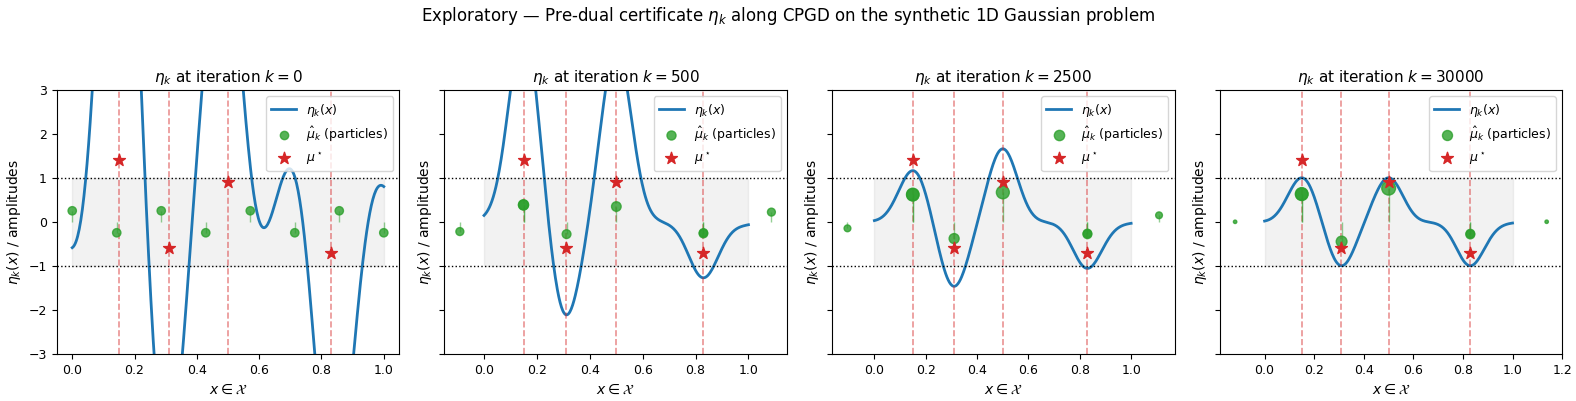

In [9]:
snapshot_iters = [0, 500, 2500, SYN_T]
fig, axes = plt.subplots(1, len(snapshot_iters), figsize=(16, 4), sharey=True)

# Re-run a *replica* to extract certificates / iterates at the snapshot iters.
particles_replay = initialize_uniform_particles(
    n_particles=SYN_N_PARTICLES, domain=(0.0, 1.0),
    weight_scale=SYN_WEIGHT_SCALE, signed=True,
)
opt_replay = ConicOptimizer(
    particles=particles_replay,
    alpha=SYN_ETA_W, beta=SYN_ETA,
    retraction=MirrorRetraction(),
)
snap_dict = {}
for k in range(SYN_T + 1):
    if k in snapshot_iters:
        snap_dict[k] = particles_replay.clone(detach=True)
    if k == SYN_T:
        break
    ev = problem_syn(particles_replay)
    ev.Jp_backward
    opt_replay.step()

for ax, k in zip(axes, snapshot_iters):
    p = snap_dict[k]
    eta_grid = problem_syn.eta_on_grid(p, syn_grid, lam=SYN_LAMBDA)
    a_signed = (p.signs * p.amplitudes).detach()
    gplt.plot_certificate_1d(
        eta_grid=eta_grid, grid=syn_grid,
        particles_positions=p.positions.detach(),
        particles_signed_amps=a_signed,
        truth_positions=synth.spike_locations,
        truth_amps=synth.spike_signs * synth.spike_amplitudes,
        cluster_radius=None,   # per-particle scatter (no cluster aggregation)
        ax=ax, title=f"$\\eta_k$ at iteration $k={k}$",
    )

fig.suptitle(
    "Exploratory — Pre-dual certificate $\\eta_k$ along CPGD on the synthetic 1D Gaussian problem",
    y=1.02, fontsize=12,
)
fig.tight_layout()
plt.show()

### Mirror Alignment check at convergence (synthetic 1D)

The KKT / Mirror-Alignment condition for the TV-regularised optimum is
$\eta(\theta_i^\star)=\mathrm{sign}(a_i^\star)$ on the support of $\mu^\star$
(saturation) and $\|\eta\|_\infty\le1$ off-support. At a finite-iteration CPGD
output both hold only approximately; we report the saturation residual
$\max_i|\eta(\hat\theta_i)-\hat s_i|$ over active particles and the off-support
violation $\max(0,\|\eta\|_\infty-1)$. This is the operational form of the
robust Mirror-Alignment bound **Theorem 2** (`thm:robust_align_first_order`).

In [10]:
ma_syn = mirror_alignment_check(
    problem=problem_syn, particles=particles_syn, lam=SYN_LAMBDA,
    grid=syn_grid,
    activity_threshold=1e-3,
    # CPGD coalesces particles into a *cluster* around each truth spike;
    # only the dominant ones at the cluster centre saturate eta exactly.
    activity_threshold_rel=0.2,
)
print_mirror_alignment(ma_syn, label="(synthetic 1D Gaussian, end of CPGD)")
print()
print("Note: CPGD with mirror retraction produces clusters of atoms around")
print("each truth spike, not isolated atoms. The Mirror-Alignment identity")
print("eta(theta_i)=sign_i is exact only at the cluster *centre* (the")
print("emerging Dirac); particles offset within sigma_phi of the centre have")
print("eta < 1 there. The recovered measure is read in the cluster sense.")

Mirror-Alignment check (synthetic 1D Gaussian, end of CPGD)
  ||eta||_inf (sup over grid) = 1.0003
  off-support violation       = max(0, sup_norm-1) = 2.90e-04
  # active particles          = 6
  max |eta(theta_i*)-sign_i*| = 0.0003  (should be small ≈ 0)
  Top-6 active particles by amplitude:
      idx      |a_i|   sign_i   eta(theta_i)    residual
        4     0.7629       +1        +1.0003      0.0003
        2     0.6338       +1        +1.0003      0.0003
        0     0.6251       +1        +1.0003      0.0003
        3     0.4492       -1        -1.0003      0.0003
        5     0.2874       -1        -1.0003      0.0003
        7     0.2702       -1        -1.0003      0.0003

Note: CPGD with mirror retraction produces clusters of atoms around
each truth spike, not isolated atoms. The Mirror-Alignment identity
eta(theta_i)=sign_i is exact only at the cluster *centre* (the
emerging Dirac); particles offset within sigma_phi of the centre have
eta < 1 there. The recovered measur

In [11]:
# Cluster-aggregated amplitude recovery (synthetic). CPGD spreads atoms around
# each truth spike; aggregating within a 3*sigma_phi window gives the recovered
# cluster mass — directly comparable to the truth spike amplitude.
err_syn = cluster_recovery_error(
    particles_syn, synth.spike_locations,
    synth.spike_amplitudes, synth.spike_signs,
    cluster_radius=3 * SYN_SIGMA_PHI, activity_threshold=1e-3,
)
print()
print("Cluster-aggregated recovery (synthetic):")
print(f"  recovered TV norm = {float(particles_syn.tv_norm()):.4f}  "
      f"(truth = {float(synth.spike_amplitudes.sum()):.4f})")
print(f"  truth (signed amp): "
      f"{[f'{float(s*a):+.3f}' for s, a in zip(synth.spike_signs, synth.spike_amplitudes)]}")
print(f"  recovered cluster amps: "
      f"{[f'{a:+.3f}' for a in err_syn['cluster_amps']]}")
print(f"  recovered cluster pos:  "
      f"{[f'{p:.4f}' for p in err_syn['cluster_pos']]}")
print(f"  truth pos:              "
      f"{[f'{float(x):.4f}' for x in synth.spike_locations.squeeze()]}")
print(f"  pos error  = {err_syn['pos_err']:.4f}")
print(f"  amp error  = {err_syn['amp_err']:.4f}  (BLASSO O(lambda) amplitude shrinkage)")
print(f"  spurious   = {err_syn['spurious_mass']:.4f}")


Cluster-aggregated recovery (synthetic):
  recovered TV norm = 3.0298  (truth = 3.6000)
  truth (signed amp): ['+1.400', '-0.600', '+0.900', '-0.700']
  recovered cluster amps: ['+1.259', '-0.449', '+0.763', '-0.558']
  recovered cluster pos:  ['0.1497', '0.3106', '0.5003', '0.8298']
  truth pos:              ['0.1500', '0.3100', '0.5000', '0.8300']
  pos error  = 0.0014
  amp error  = 0.5715  (BLASSO O(lambda) amplitude shrinkage)
  spurious   = 0.0000


---
# Algorithmic interpretation: Lion-K and Muon (§5.3)

Two non-convex optimisers widely used in deep learning — **Lion-K**
[Chen et al. 2023] and **Muon** [Jordan et al. 2024] — are built on the same
Mirror-Alignment nonlinearities (§2) as the regularizers of the §4
catalogue (`sec:applications`): Lion's $\mathrm{sign}$ step is a subgradient of
the $\ell_1$ norm, and Muon's matrix-sign step $UV^\top$ a subgradient of the
nuclear norm.

Here we **reconsider both optimisers so that they solve the *same* regularised
program $F+\lambda R$ as ISTA / SVT**, by using the sign / matsign nonlinearity
as the regulariser's **proximal operator** rather than as weight decay:

- **§A.** $\ell_1$ — soft-thresholding $\mathrm{soft}_\tau(z)=\mathrm{sign}(z)\,
  \max(|z|-\tau,0)$ *is* the prox of $\lambda\|\cdot\|_1$ built from Lion's
  $\mathrm{sign}$ step (proximal Lion-K $=$ ISTA).
- **§B.** nuclear — singular-value thresholding
  $U\,\mathrm{soft}_\tau(\Sigma)\,V^\top$ is the prox of $\lambda\|\cdot\|_*$,
  with the polar factor $UV^\top$ supplied by Muon's matrix-sign / Polar-Express
  step (proximal Muon $=$ SVT).

In this proximal form **all four optimisers solve exactly the same $F+\lambda R$
program**, and the oracle-free Fenchel–Young gap $\Delta_t=L_F+\lambda L_R$
(**Theorem 1**, `thm:dual_gap`) **certifies every one of them** — $\Delta_t\to0$
— exactly as it certifies CPGD in §5.1–§5.2. The paper's Figure 1 (regenerated below) shows this.

Both demos are short, finite-dimensional, and use only `numpy`+`torch.linalg`.

## §A — Lion-K (proximal sign-thresholding) solves $F+\lambda R$ for $\ell_1$

**Problem.** Sparse linear regression
$\min_x J(x)=\tfrac12\|Ax-y\|_2^2 + \lambda\|x\|_1$ with $A\in\mathbb{R}^{n\times d}$
Gaussian, $x^\star$ $k$-sparse, $y=Ax^\star+\sigma w$.

**ISTA $=$ proximal Lion-K.**
$x_{t+1}=\mathrm{soft}_{\eta\lambda}(x_t-\eta A^\top(Ax_t-y))$, where the prox of
$\lambda\|\cdot\|_1$ is the **sign-shrinkage**
$\mathrm{soft}_\tau(z)=\mathrm{sign}(z)\,\max(|z|-\tau,0)$ — Lion's $\mathrm{sign}$
step used as the regulariser's proximal operator. This is exactly the
$F+\lambda R$ proximal-gradient iteration, so $x_t$ converges to the
$F+\lambda R$ optimum and the Fenchel–Young gap $\Delta_t\to0$.

**What we illustrate.** (i) the oracle-free gap $\Delta_t=L_F+\lambda L_R$
(**Theorem 1**) decreases to $0$ along the trajectory — *certification of the
deep-learning-style optimiser*; (ii) at the optimum the certificate
$-\nabla F(\hat x)/\lambda$ lies in $[-1,1]^d$ and saturates $\pm1$ on the active
support, i.e. $-\nabla F(\hat x)/\lambda\in\partial\|\hat x\|_1$ (the
regulariser-side Mirror Alignment).

In [12]:
def soft_threshold(z, tau):
    # prox of tau*||.||_1: Lion's sign step used as the regulariser prox
    return torch.sign(z) * torch.clamp(z.abs() - tau, min=0.0)

def delta_l1(x, A, y, lam):
    r"""Honest Fenchel--Young gap for $\min_x \tfrac12\|Ax-y\|^2+\lambda\|x\|_1$.

    Builds the rescaled Mirror-Alignment dual $\tilde h=c\,h$, $h=Ax-y$, with
    contraction $c=\min(1,\lambda/\|A^\top h\|_\infty)\in[0,1]$ so $\tilde h\in
    K_\lambda$. Returns $(\Delta,\,L_F,\,\lambda L_R)$ with
    $\Delta=\tfrac12(1-c)^2\|Ax-y\|^2+\lambda(\|x\|_1-\langle c\eta,x\rangle)
    \ge J(x)-\inf J$ (**Theorem 1**, `thm:dual_gap`)."""
    h = A @ x - y
    AT_h = A.T @ h
    M = float(AT_h.abs().max())
    c = min(1.0, lam / max(M, 1e-30))
    eta_tilde = -c * AT_h / lam
    L_F = 0.5 * (1.0 - c) ** 2 * float(h.pow(2).sum())
    lam_L_R = lam * float(x.abs().sum() - eta_tilde @ x)
    return max(0.0, L_F + lam_L_R), L_F, lam_L_R

def ista(A, y, lam, eta, T, x0=None):
    """Proximal-gradient (= proximal Lion-K): the prox is the sign-shrinkage
    soft-threshold, so this solves min 1/2||Ax-y||^2 + lam||x||_1 exactly.
    Records the FY gap Delta_t = L_F + lam*L_R and its two pieces each step.
    `losses` is the objective J(x_t) (used for the oracle gap in Figure 3)."""
    x = torch.zeros(A.shape[1], dtype=A.dtype) if x0 is None else x0.clone()
    losses, deltas, L_Fs, lam_L_Rs = [], [], [], []
    for _ in range(T):
        g = A.T @ (A @ x - y)
        x = soft_threshold(x - eta * g, eta * lam)
        d, lf, lr = delta_l1(x, A, y, lam)
        losses.append(0.5 * float((A @ x - y).pow(2).sum()) + lam * float(x.abs().sum()))
        deltas.append(d); L_Fs.append(lf); lam_L_Rs.append(lr)
    return x, losses, deltas, L_Fs, lam_L_Rs

In [13]:
torch.manual_seed(0)
N_LION, D_LION, K_LION = 60, 80, 5
A = torch.randn(N_LION, D_LION) / np.sqrt(N_LION)
x_star = torch.zeros(D_LION)
support_star = torch.randperm(D_LION)[:K_LION]
x_star[support_star] = torch.randn(K_LION).sign() * (1.0 + 0.5 * torch.rand(K_LION))
y_lion = A @ x_star + 0.05 * torch.randn(N_LION)

LAM_LION = 0.05
ETA_LION = 0.5
T_LION = 5_000          # ample iterations: support stabilises by t~2000

# Proximal Lion-K (= ISTA): solves min 1/2||Ax-y||^2 + lam||x||_1 exactly.
x_ista, losses_ista, d_ista, lf_ista, lr_ista = ista(
    A, y_lion, LAM_LION, ETA_LION, T_LION)

# Mirror-Alignment certificate at the optimum:
g_ista = A.T @ (A @ x_ista - y_lion)
cert_ista = -g_ista / LAM_LION

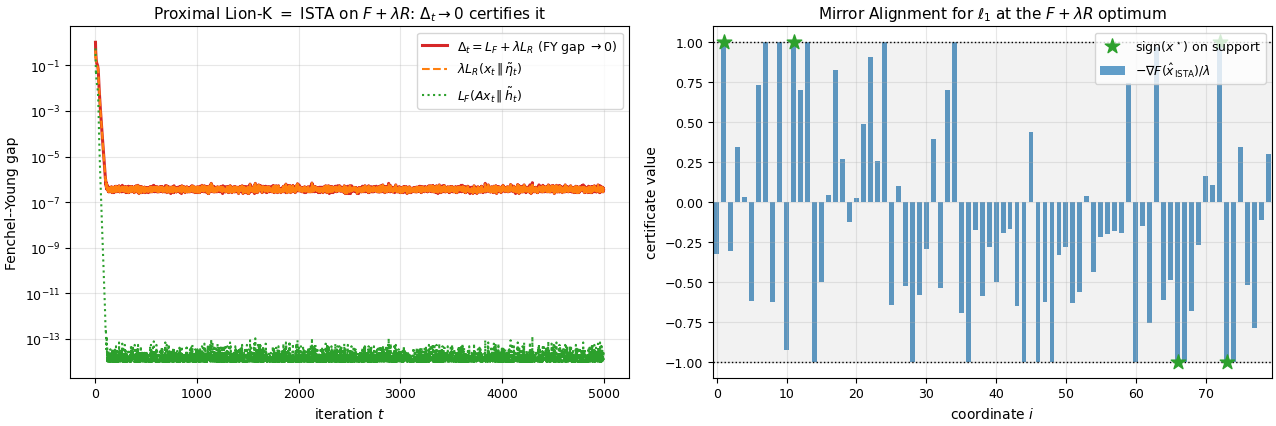

Proximal Lion-K (= ISTA) on F + lambda*||.||_1:
  final FY gap Delta_T                        = 3.815e-07  (-> 0)
  certificate -g/lam in [-1,1]^d ?  max |.|   = 1.000  (<= 1 at optimum)
  recovered support (|x_i|>1e-3)              : 19  (truth = 5)
  saturated-certificate support |c|>.99      : 19  (truth = 5)  <- MA-aligned notion
  -> soft-threshold = sign(z)*relu(|z|-tau) is Lion's sign step used as the
     l1 prox: the iterate solves F+lambda*R exactly and Delta_t certifies it.


In [14]:
fig, (axA, axB) = plt.subplots(1, 2, figsize=(13, 4.5))

# FY-gap decomposition along proximal Lion-K (= ISTA): Delta_t = L_F + lam*L_R -> 0.
EPS = 1e-14
axA.plot(np.maximum(np.array(d_ista), EPS), color="C3", linewidth=2.2,
         label=r"$\Delta_t = L_F + \lambda L_R$ (FY gap $\to 0$)")
axA.plot(np.maximum(np.array(lr_ista), EPS), color="C1", linewidth=1.5,
         linestyle="--", label=r"$\lambda L_R(x_t\,\|\,\tilde\eta_t)$")
axA.plot(np.maximum(np.array(lf_ista), EPS), color="C2", linewidth=1.5,
         linestyle=":", label=r"$L_F(Ax_t\,\|\,\tilde h_t)$")
axA.set_yscale("log")
axA.set_xlabel("iteration $t$")
axA.set_ylabel("Fenchel--Young gap")
axA.set_title(r"Proximal Lion-K $=$ ISTA on $F+\lambda R$: $\Delta_t\to0$ certifies it")
axA.grid(True, which="both", alpha=0.3); axA.legend(fontsize=9)

# Mirror-Alignment certificate at the optimum
xs = np.arange(D_LION)
axB.bar(xs, cert_ista.numpy(), width=0.7, color="C0", alpha=0.7,
        label=r"$-\nabla F(\hat x_{\rm ISTA})/\lambda$")
support_idx = support_star.numpy()
truth_signs_on_support = np.sign(x_star[support_star].detach().numpy())
axB.scatter(xs[support_idx], truth_signs_on_support,
            color="C2", marker="*", s=120, zorder=5,
            label=r"$\mathrm{sign}(x^\star)$ on support")
axB.axhline(1.0, color="black", linestyle=":", linewidth=1)
axB.axhline(-1.0, color="black", linestyle=":", linewidth=1)
axB.fill_between([-0.5, D_LION - 0.5], -1, 1, color="black", alpha=0.05)
axB.set_xlim(-0.5, D_LION - 0.5)
axB.set_xlabel("coordinate $i$")
axB.set_ylabel("certificate value")
axB.set_title(r"Mirror Alignment for $\ell_1$ at the $F+\lambda R$ optimum")
axB.grid(True, alpha=0.3); axB.legend(fontsize=9, loc="upper right")
fig.tight_layout()
plt.show()

print("Proximal Lion-K (= ISTA) on F + lambda*||.||_1:")
print(f"  final FY gap Delta_T                        = {d_ista[-1]:.3e}  (-> 0)")
print(f"  certificate -g/lam in [-1,1]^d ?  max |.|   = {cert_ista.abs().max():.3f}"
      f"  (<= 1 at optimum)")
ista_supp_amp = int((x_ista.abs() > 1e-3).sum())
ista_supp_sat = int((cert_ista.abs() > 0.99).sum())
print(f"  recovered support (|x_i|>1e-3)              : {ista_supp_amp}  (truth = {K_LION})")
print(f"  saturated-certificate support |c|>.99      : {ista_supp_sat}  "
      f"(truth = {K_LION})  <- MA-aligned notion")
print("  -> soft-threshold = sign(z)*relu(|z|-tau) is Lion's sign step used as the")
print("     l1 prox: the iterate solves F+lambda*R exactly and Delta_t certifies it.")

### Mirror Alignment "saturation" check at ISTA optimum

At the ISTA optimum $\hat x$ we read the certificate $-\nabla F(\hat x)/\lambda$
at every active coordinate and compare it to $\mathrm{sign}(\hat x_i)$; the
Mirror-Alignment / KKT identity demands equality to numerical tolerance — the
$\ell_1$ analogue of $\eta(\theta_i^\star)=s_i^\star$ in the synthetic 1D case.

In [15]:
ista_active = (x_ista.abs() > 1e-3)
ista_active_idx = torch.where(ista_active)[0]
ista_active_signs = torch.sign(x_ista[ista_active_idx])
ista_cert_active = cert_ista[ista_active_idx]
ista_ma_residual = (ista_cert_active - ista_active_signs).abs()

print("Mirror-Alignment saturation check (ISTA, ℓ₁):")
print(f"  ||cert||_inf (off-support bound)     = {cert_ista.abs().max():.4f}")
print(f"  off-support violation                = "
      f"{max(0.0, float(cert_ista.abs().max() - 1.0)):.2e}")
print(f"  max |cert(i) - sign(x_i)|, i active  = {float(ista_ma_residual.max()):.4e}  "
      f"(should be ≈ 0)")
print(f"  per-active-coordinate (idx, |x|, sign, cert, residual):")
for i, idx in enumerate(ista_active_idx.tolist()):
    print(f"    {idx:>3}  {x_ista[idx].abs():.4f}  "
          f"{int(ista_active_signs[i]):+d}  "
          f"{cert_ista[idx]:+.4f}  {ista_ma_residual[i]:.2e}")

Mirror-Alignment saturation check (ISTA, ℓ₁):
  ||cert||_inf (off-support bound)     = 1.0000
  off-support violation                = 4.77e-07
  max |cert(i) - sign(x_i)|, i active  = 2.1458e-06  (should be ≈ 0)
  per-active-coordinate (idx, |x|, sign, cert, residual):
      1  0.9809  +1  +1.0000  2.15e-06
      7  0.0021  +1  +1.0000  1.19e-07
      9  0.0352  +1  +1.0000  3.58e-07
     11  1.2621  +1  +1.0000  0.00e+00
     13  0.0320  +1  +1.0000  2.98e-07
     14  0.0104  -1  -1.0000  4.77e-07
     24  0.0237  +1  +1.0000  1.19e-07
     28  0.0153  -1  -1.0000  1.19e-07
     34  0.0550  +1  +1.0000  3.58e-07
     36  0.0027  -1  -1.0000  1.19e-07
     44  0.0213  -1  -1.0000  1.19e-07
     46  0.0126  -1  -1.0000  3.58e-07
     48  0.0046  -1  -1.0000  1.19e-07
     60  0.0236  -1  -1.0000  3.58e-07
     66  1.3426  -1  -1.0000  0.00e+00
     67  0.0252  -1  -1.0000  0.00e+00
     72  0.9943  +1  +1.0000  2.38e-07
     73  1.1171  -1  -1.0000  1.79e-06
     74  0.0230  -1  -1.000

**Reading the ℓ₁ Mirror Alignment.** In its proximal form (soft-thresholding),
Lion-K *is* ISTA and solves the $F+\lambda R$ program; the FY gap
$\Delta_t=L_F+\lambda L_R\to0$ certifies it without any oracle. At the optimum
the certificate $-\nabla F(\hat x)/\lambda$ lies in $[-1,1]^d$ and saturates
$\pm1$ at every active coordinate (residuals $\sim10^{-6}$) — the operational
form of $-\nabla F(\hat x)/\lambda\in\partial\|\hat x\|_1$. The right
Mirror-Alignment notion of "support" is the saturated-certificate set, not an
amplitude threshold.

## §B — Muon (proximal matsign-thresholding) solves $F+\lambda R$ for the nuclear norm

**Problem.** Low-rank matrix denoising
$\min_X J(X)=\tfrac12\|X-Y\|_F^2+\lambda\|X\|_*$ with $Y=X^\star+\sigma W$,
$X^\star$ of rank $r$.

**SVT $=$ proximal Muon.** Singular-value thresholding
$X_{t+1}=U\,\mathrm{soft}_{\eta\lambda}(\Sigma)\,V^\top$ from the SVD of
$X_t-\eta(X_t-Y)$ is the prox of $\lambda\|\cdot\|_*$. The polar factor $UV^\top$
of the SVD is exactly Muon's matrix-sign / Polar-Express step (quintic
Newton–Schulz [Amsel et al. 2026]); applying the **same** sign nonlinearity to
the *singular values* $\Sigma$ gives the regulariser prox. So proximal Muon is
SVT and solves the $F+\lambda R$ program; the FY gap $\Delta_t=L_F+\lambda L_R$
certifies it, $\Delta_t\to0$.

**What we illustrate.** (i) $\Delta_t\to0$ along the trajectory (oracle-free
certification of the deep-learning-style optimiser); (ii) the recovered spectrum
truncates the noisy singular values to the rank-3 truth with the $\lambda$
shrinkage characteristic of the $F+\lambda R$ optimum.

In [16]:
def matsign_ns(G, n_iter=12, order=5):
    """Higher-order Newton–Schulz iterations for the matrix sign UV^T.

    order=3 (cubic): Y_{k+1}=(1/2)Y(3I-Y^TY).
    order=5 (quintic): Y_{k+1}=(1/8)Y(15I-10 Y^TY+3(Y^TY)^2) — Polar Express
    [Amsel et al. 2026]. Initialised by the spectral norm of G so ||Y_0||_op=1.
    """
    s_max = float(torch.linalg.svdvals(G)[0]) + 1e-12
    Y = G / s_max
    I = torch.eye(min(Y.shape), dtype=Y.dtype, device=Y.device)
    for _ in range(n_iter):
        if Y.shape[0] >= Y.shape[1]:
            YtY = Y.T @ Y
            if order == 3:
                Y = 0.5 * (Y @ (3 * I - YtY))
            elif order == 5:
                YtY2 = YtY @ YtY
                Y = (1.0 / 8.0) * (Y @ (15 * I - 10 * YtY + 3 * YtY2))
            else:
                raise ValueError("order must be 3 or 5")
        else:
            YYt = Y @ Y.T
            if order == 3:
                Y = 0.5 * ((3 * I - YYt) @ Y)
            elif order == 5:
                YYt2 = YYt @ YYt
                Y = (1.0 / 8.0) * ((15 * I - 10 * YYt + 3 * YYt2) @ Y)
    return Y

def delta_nuclear(X, Y, lam):
    r"""Honest Fenchel--Young gap for $\min_X \tfrac12\|X-Y\|_F^2+\lambda\|X\|_*$.

    Dual feasibility is $\|H\|_{\rm op}\le\lambda$. With $H=X-Y$, contraction
    $c=\min(1,\lambda/\|H\|_{\rm op})$, $\tilde Z=-c\,H/\lambda$ has
    $\|\tilde Z\|_{\rm op}\le1$. Returns $(\Delta,\,L_F,\,\lambda L_R)$ with
    $\Delta=\tfrac12(1-c)^2\|X-Y\|_F^2+\lambda(\|X\|_*-\langle\tilde Z,X\rangle)$."""
    H = X - Y
    op_norm = float(torch.linalg.svdvals(H)[0])
    c = min(1.0, lam / max(op_norm, 1e-30))
    Z_tilde = -c * H / lam
    L_F = 0.5 * (1.0 - c) ** 2 * float(H.pow(2).sum())
    lam_L_R = lam * (float(torch.linalg.svdvals(X).sum()) - float((Z_tilde * X).sum()))
    return max(0.0, L_F + lam_L_R), L_F, lam_L_R

def svt(Y, lam, eta, T, X0=None):
    """Singular-value thresholding (= proximal Muon): the prox of lam*||.||_*
    truncates the singular values with the same sign-shrinkage as Lion's step,
    while the polar factor UV^T is Muon's matrix-sign direction. Solves
    min 1/2||X-Y||_F^2 + lam||X||_* exactly; records the FY gap each step."""
    X = Y.clone() if X0 is None else X0.clone()
    losses, deltas, L_Fs, lam_L_Rs = [], [], [], []
    for _ in range(T):
        Z = X - eta * (X - Y)
        U, S, Vh = torch.linalg.svd(Z, full_matrices=False)
        S = torch.clamp(S - eta * lam, min=0.0)
        X = (U * S.unsqueeze(0)) @ Vh
        d, lf, lr = delta_nuclear(X, Y, lam)
        losses.append(0.5 * float((X - Y).pow(2).sum()) + lam * float(S.sum()))
        deltas.append(d); L_Fs.append(lf); lam_L_Rs.append(lr)
    return X, losses, deltas, L_Fs, lam_L_Rs

In [17]:
torch.manual_seed(0)
M_MUON, R_MUON = 25, 3
U_star = torch.linalg.qr(torch.randn(M_MUON, R_MUON))[0]
V_star = torch.linalg.qr(torch.randn(M_MUON, R_MUON))[0]
S_star = torch.tensor([3.0, 2.0, 1.5])
X_star = (U_star * S_star.unsqueeze(0)) @ V_star.T   # (M, M), rank R

# Noise level so that ||W||_op ~ 2*sigma*sqrt(M) sits below the soft-thresholding
# scale lam, i.e. SVT recovers the rank-R truth cleanly with mild shrinkage.
SIGMA_W_MUON = 0.05
Y_muon = X_star + SIGMA_W_MUON * torch.randn(M_MUON, M_MUON)

LAM_MUON = 0.5
ETA_SVT = 0.5
T_MUON = 200

# Proximal Muon (= SVT): solves min 1/2||X-Y||_F^2 + lam||X||_* exactly.
X_svt, losses_svt, d_svt, lf_svt, lr_svt = svt(Y_muon, LAM_MUON, ETA_SVT, T_MUON)

# Sanity: matsign output vs the exact SVD-based UV^T (Muon's matrix-sign step)
G_test = X_svt - Y_muon
matsign_ns_value = matsign_ns(G_test, n_iter=8)
U_, _, Vh_ = torch.linalg.svd(G_test, full_matrices=False)
matsign_svd_value = U_ @ Vh_
err_matsign = float((matsign_ns_value - matsign_svd_value).norm()
                     / (matsign_svd_value.norm() + 1e-12))
print(f"  Newton–Schulz matsign vs SVD-based UV^T: relative error = {err_matsign:.2e}")

  Newton–Schulz matsign vs SVD-based UV^T: relative error = 3.31e-04


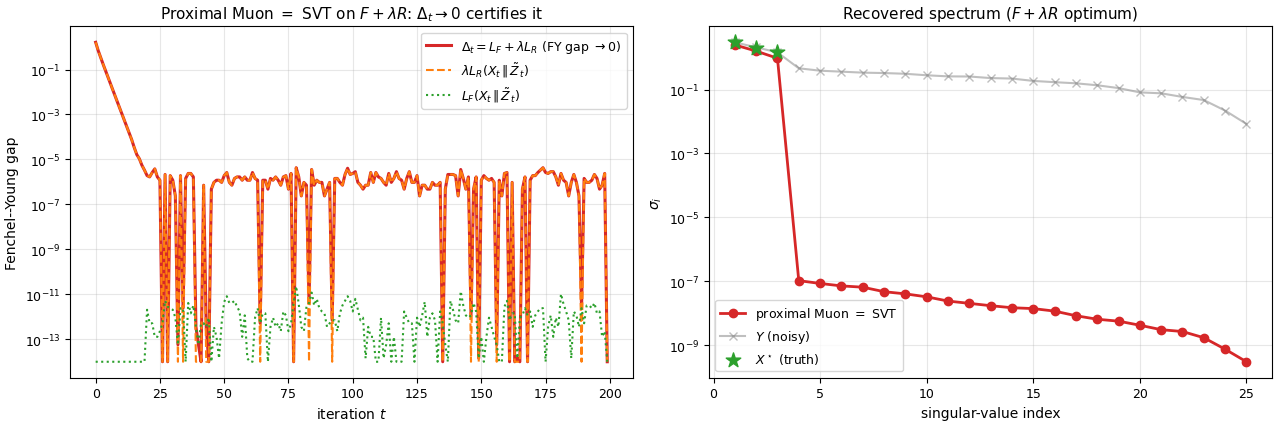

In [18]:
fig, (axA, axB) = plt.subplots(1, 2, figsize=(13, 4.5))

# FY-gap decomposition along proximal Muon (= SVT): Delta_t = L_F + lam*L_R -> 0.
EPS = 1e-14
axA.plot(np.maximum(np.array(d_svt), EPS), color="C3", linewidth=2.2,
         label=r"$\Delta_t = L_F + \lambda L_R$ (FY gap $\to 0$)")
axA.plot(np.maximum(np.array(lr_svt), EPS), color="C1", linewidth=1.5,
         linestyle="--", label=r"$\lambda L_R(X_t\,\|\,\tilde Z_t)$")
axA.plot(np.maximum(np.array(lf_svt), EPS), color="C2", linewidth=1.5,
         linestyle=":", label=r"$L_F(X_t\,\|\,\tilde Z_t)$")
axA.set_yscale("log")
axA.set_xlabel("iteration $t$")
axA.set_ylabel("Fenchel--Young gap")
axA.set_title(r"Proximal Muon $=$ SVT on $F+\lambda R$: $\Delta_t\to0$ certifies it")
axA.grid(True, which="both", alpha=0.3); axA.legend(fontsize=9)

# Singular-value spectrum of the recovered matrix
sv_svt = torch.linalg.svdvals(X_svt).numpy()
sv_truth = S_star.numpy()
sv_obs = torch.linalg.svdvals(Y_muon).numpy()
xs = np.arange(1, len(sv_svt) + 1)
axB.plot(xs, sv_svt, "o-", color="C3", linewidth=2,
         label="proximal Muon $=$ SVT")
axB.plot(np.arange(1, len(sv_obs) + 1), sv_obs, "x-",
         color="gray", alpha=0.5, label="$Y$ (noisy)")
axB.scatter(np.arange(1, len(sv_truth) + 1), sv_truth, color="C2", marker="*",
            s=120, zorder=5, label=r"$X^\star$ (truth)")
axB.set_yscale("log")
axB.set_xlabel("singular-value index")
axB.set_ylabel("$\\sigma_i$")
axB.set_title("Recovered spectrum ($F+\\lambda R$ optimum)")
axB.grid(True, which="both", alpha=0.3); axB.legend()
fig.tight_layout()
plt.show()

**Reading the nuclear-norm Mirror Alignment.** In its proximal form (SVT),
Muon solves the $F+\lambda R$ program and the FY gap $\Delta_t\to0$ certifies
it. The recovered spectrum truncates the noisy singular values to the rank-3
truth, with $(3,2,1.5)$ shifted down by $\lambda$ — the nuclear-norm analogue
of the BLASSO amplitude shrinkage in the synthetic 1D experiment. Muon's
matrix-sign step is the regulariser-side Mirror Alignment for the nuclear norm:
at a rank-$r$ optimum $\hat X=U\Sigma V^\top$,
$\mathrm{matsign}(-\nabla F(\hat X)/\lambda)=UV^\top\in\partial\|\hat X\|_*$, the
spectral analogue of $\mathrm{sign}(z)\in\mathrm{Sgn}(\hat x)$.

### Mirror Alignment "saturation" check at SVT optimum

At the SVT fixed point $\hat X=\hat U\hat\Sigma\hat V^\top$ the optimality
condition reads $-\nabla F(\hat X)/\lambda=\hat U\hat V^\top+W\in\partial\|\hat
X\|_*$ with $\|W\|_{\rm op}\le1$, $\hat U^\top W=0$, $W\hat V=0$. We verify
spectral feasibility ($\|-\nabla F(\hat X)/\lambda\|_{\rm op}\le1$) and
saturation on the active span ($\mathrm{matsign}|_{\text{rank-}r}=\hat U\hat V^\top$).

In [19]:
G_svt = X_svt - Y_muon                               # nabla F(X_svt) (LSQ)
cert_svt = -G_svt / LAM_MUON                         # spectral certificate

cert_op = float(torch.linalg.svdvals(cert_svt)[0])   # spectral norm

# Top-r SVD of cert_svt
U_c, S_c, Vh_c = torch.linalg.svd(cert_svt, full_matrices=False)
r_active = int((S_c > 0.99).sum())   # active = saturated singular values
matsign_cert_topr = U_c[:, :r_active] @ Vh_c[:r_active, :]

# UV^T from the SVT iterate
U_x, S_x, Vh_x = torch.linalg.svd(X_svt, full_matrices=False)
r_x = int((S_x > 1e-4).sum())
U_x_r, Vh_x_r = U_x[:, :r_x], Vh_x[:r_x, :]
UVt_xsvt = U_x_r @ Vh_x_r

print("Mirror-Alignment saturation check (Muon / SVT, nuclear norm):")
print(f"  ||-grad F/lam||_op (spectral norm)        = {cert_op:.4f}  "
      f"(should be ≤ 1 at optimum)")
print(f"  off-support violation                     = "
      f"{max(0.0, cert_op - 1.0):.2e}")
print(f"  rank of X_svt (active singular values)    = {r_x}")
print(f"  # saturated certificate sing. vals (≈ 1)  = {r_active}")
print(f"  Top-r singular values of cert            : "
      f"{S_c[:max(r_active, r_x)].tolist()}")
print(f"  || cert.matsign|_top-r  -  U_x V_x^T ||_F = "
      f"{float((matsign_cert_topr - UVt_xsvt).norm()):.2e}  "
      f"(saturation alignment, should be ≈ 0)")

Mirror-Alignment saturation check (Muon / SVT, nuclear norm):
  ||-grad F/lam||_op (spectral norm)        = 1.0000  (should be ≤ 1 at optimum)
  off-support violation                     = 0.00e+00
  rank of X_svt (active singular values)    = 3
  # saturated certificate sing. vals (≈ 1)  = 3
  Top-r singular values of cert            : [1.0000005960464478, 0.9999997615814209, 0.999999463558197]
  || cert.matsign|_top-r  -  U_x V_x^T ||_F = 6.24e-06  (saturation alignment, should be ≈ 0)


## §C — Takeaways

| Algorithm | Regularizer $R$ | Mirror-Alignment nonlinearity $\in\partial R$ | Proximal step (solves $F+\lambda R$) | $\Delta_t\to0$? |
|---|---|---|---|---|
| Lion-K  | $\ell_1$ | $\mathrm{sign}(z)\in\partial\|z\|_1$ | soft-threshold $\mathrm{sign}(z)\max(|z|-\tau,0)$ $=$ ISTA | yes |
| Muon    | nuclear norm | $UV^\top\in\partial\|U\Sigma V^\top\|_*$ | singular-value threshold $=$ SVT | yes |
| CPGD    | TV (continuous) | $\eta_0^\star\in\partial\|\mu^\star\|_{\mathrm{TV}}$ | mirror retraction on amplitudes | yes |

Each row exhibits the same pattern: the optimiser's sign / matsign / mirror
nonlinearity is a subgradient of the regulariser, and when used as the
regulariser's **proximal** step the method solves the *same* $F+\lambda R$
program — certified, oracle-free, by the Fenchel–Young gap $\Delta_t\to0$
(**Theorem 1**). The paper's contribution (§1.1 `subsec:contributions`) is to
identify this *common* principle, quantify it via the Fenchel–Young error bounds of
§2 (**Theorems 2–3**), and turn it into an exact-recovery + early-stopping
certificate via the Brøndsted–Rockafellar theorem of §3 (**Theorem 4**,
`thm:algorithmic_stability`). §5.3 shows the same Mirror-Alignment logic
underlies two state-of-the-art deep-learning optimisers — and that the duality
gap certifies them on the common $F+\lambda R$ program.

---
# Paper I figures (Figures 1–3 of `main_FY_gap.tex`)

The three publication figures, saved into `FIGS_DIR` where the LaTeX source
references them as `\includegraphics{figs/<name>}`.

## Paper I, Figure 2 — Dual certificate evolution (`fig:certificate_evolution`, §5.1)

Four CPGD snapshots. Each panel overlays the raw certificate $\eta_k$, the
rescaled $\tilde\eta_k=c_k\eta_k$ (with $c_k=\min(1,1/\|\eta_k\|_\infty)$),
the **recovered BLASSO solution $\hat\mu_k$** (green stems at each active
particle, signed amplitude on the $y$-axis), and the truth $\mu^\star$
(red stars), with the oracle-free Fenchel–Young gap $\Delta_k$ (Theorem 1,
`thm:dual_gap`) in the inset. Reuses `snap_dict`.

Saved /Users/yohann/Library/CloudStorage/Dropbox/0_Yohann/7_Code/2026_FYL_gap/fenchel-young-gaps/figs/fig_certificate_evolution.pdf


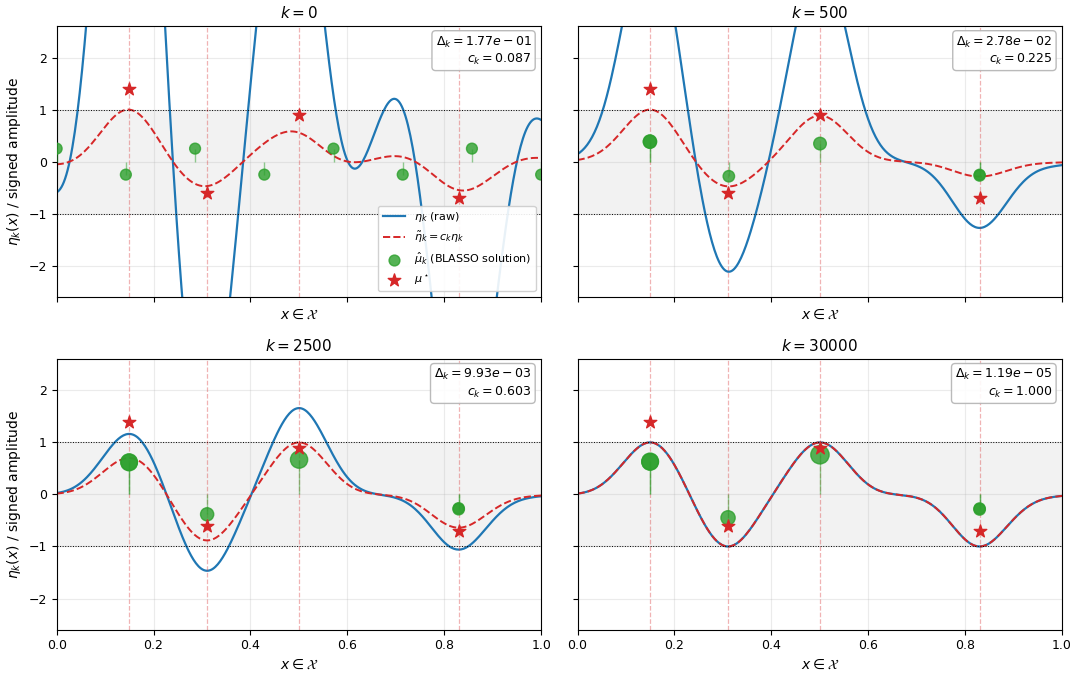

In [20]:
def _draw_certificate_panel(ax, p, eta_grid, lam, syn_grid, synth, k):
    g = syn_grid.squeeze().detach().cpu().numpy()
    eta = eta_grid.detach().cpu().numpy()
    sup_eta = float(np.max(np.abs(eta)))
    c_k = min(1.0, 1.0 / max(sup_eta, 1e-30))
    tilde_eta = c_k * eta
    ax.plot(g, eta, color="C0", linewidth=1.6, label=r"$\eta_k$ (raw)")
    ax.plot(g, tilde_eta, color="C3", linewidth=1.4, linestyle="--",
            label=r"$\tilde\eta_k = c_k\eta_k$")
    ax.axhline(1.0, color="black", linestyle=":", linewidth=0.7)
    ax.axhline(-1.0, color="black", linestyle=":", linewidth=0.7)
    ax.fill_between(g, -1.0, 1.0, color="black", alpha=0.05)

    pos = p.positions.squeeze().detach().cpu()
    a_signed = (p.signs * p.amplitudes).detach().cpu()
    truth_x = synth.spike_locations.squeeze().detach().cpu()
    truth_a = (synth.spike_signs * synth.spike_amplitudes).detach().cpu()

    # Honest Fenchel-Young duality gap Delta_k = L_F + lambda * L_R at the
    # rescaled MA dual tilde h_k = c_k h_k in K_lambda.
    with torch.no_grad():
        eta_at_p = problem_syn.eta_on_grid(p, p.positions, lam=lam)
        TV_k = float(p.tv_norm())
        L_R = TV_k - c_k * float(eta_at_p @ a_signed)
        L_F = float(problem_syn(p).proximity) * (1.0 - c_k) ** 2
        delta_k = L_F + lam * L_R
    ax.text(0.98, 0.97,
            rf"$\Delta_k = {delta_k:.2e}$" + "\n"
            rf"$c_k = {c_k:.3f}$",
            transform=ax.transAxes, ha="right", va="top",
            fontsize=9,
            bbox=dict(boxstyle="round,pad=0.3", facecolor="white",
                      edgecolor="0.7", alpha=0.9))

    # Recovered BLASSO solution mu_hat_k as individual particles (no cluster
    # aggregation): a uniform cloud at k=0 that concentrates onto the spikes by
    # k=T. Marker size grows with |amplitude| so the surviving (concentrating)
    # atoms stand out from the dying uniform background.
    m = a_signed.abs() > 1e-4
    sizes = 6.0 + 220.0 * a_signed[m].abs().numpy()
    ax.vlines(pos[m].numpy(), 0.0, a_signed[m].numpy(),
              color="C2", linewidth=1.0, alpha=0.5, zorder=3)
    ax.scatter(pos[m].numpy(), a_signed[m].numpy(),
               color="C2", s=sizes, alpha=0.8, zorder=4,
               label=(r"$\hat\mu_k$ (BLASSO solution)" if k == 0 else None))

    # Truth markers
    for x_j in truth_x.tolist():
        ax.axvline(float(x_j), color="C3", alpha=0.35, linewidth=0.9,
                   linestyle="--")
    ax.scatter(truth_x.numpy(), truth_a.numpy(),
               color="C3", marker="*", s=90, zorder=6,
               label=r"$\mu^\star$" if k == 0 else None)

    ax.set_xlabel("$x \\in \\mathcal{X}$")
    ax.set_ylim(-2.6, 2.6)
    ax.set_xlim(0.0, 1.0)
    ax.set_title(f"$k = {k}$")
    ax.grid(True, alpha=0.25)


fig1, axes1 = plt.subplots(2, 2, figsize=(11, 7), sharey=True, sharex=True)
for ax, k in zip(axes1.flat, [0, 500, 2500, SYN_T]):
    p_k = snap_dict[k]
    eta_k = problem_syn.eta_on_grid(p_k, syn_grid, lam=SYN_LAMBDA)
    _draw_certificate_panel(ax, p_k, eta_k, SYN_LAMBDA, syn_grid, synth, k=k)
for ax in axes1[:, 0]:
    ax.set_ylabel(r"$\eta_k(x)$ / signed amplitude")
axes1[0, 0].legend(loc="lower right", fontsize=8, framealpha=0.9)
fig1.tight_layout()
fig1.savefig(FIGS_DIR / "fig_certificate_evolution.pdf")
print(f"Saved {FIGS_DIR / 'fig_certificate_evolution.pdf'}")
plt.show()

## Paper I, Figure 3 — Fenchel–Young decomposition (`fig:fy_decomposition_synthetic`, §5.2)

Single panel of the FY-tracker quantities along the synthetic-1D CPGD
trajectory. The certifiable signal $\lambda L_R$ decays at the Frank–Wolfe
$\mathcal{O}(1/k)$ rate; the total $\Delta_k\ge J(\mu_k)-\inf J$ is the
oracle-free gap of **Theorem 1** (`thm:dual_gap`). Reuses `tracker_syn`.
The blue optimality-gap curve uses $\hat J^\star=$ `SYN_J_STAR`, computed from
the extended reference run (min over the tail $(T, 2T]$), so it stays
strictly positive instead of collapsing to machine precision at the last
displayed iterate.

Saved /Users/yohann/Library/CloudStorage/Dropbox/0_Yohann/7_Code/2026_FYL_gap/fenchel-young-gaps/figs/fig_fy_decomposition_synthetic.pdf


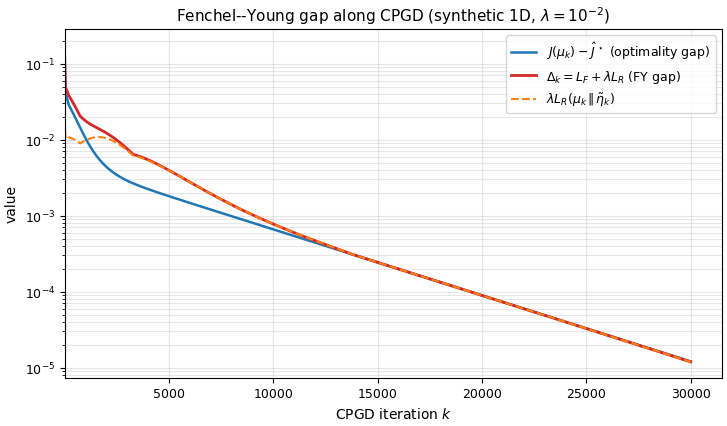

In [21]:
fig2, ax2 = plt.subplots(1, 1, figsize=(7.5, 4.5))
gplt.plot_fy_decomposition(
    tracker_syn, lam=SYN_LAMBDA, ax=ax2,
    title=r"Fenchel--Young gap along CPGD (synthetic 1D, $\lambda = 10^{-2}$)",
    show_L_F=False,      # drop the L_F curve (keep Delta_k, lambda*L_R, optimality gap)
    J_star=SYN_J_STAR,   # reference from the extended run, so J(mu_k)-hat J* stays > 0
)
ax2.set_xlim(left=10.0)
fig2.tight_layout()
fig2.savefig(FIGS_DIR / "fig_fy_decomposition_synthetic.pdf")
print(f"Saved {FIGS_DIR / 'fig_fy_decomposition_synthetic.pdf'}")
plt.show()

## Paper I, Figure 1 — Certifiability of Lion-K and Muon (`fig:lion_muon_delta`, §5.3)

**All optimisers solve the *same* $F+\lambda R$ program.**
Lion-K's $\mathrm{sign}$ step and Muon's matrix-sign step are subgradients of
the $\ell_1$ and nuclear-norm regularizers; used as the regulariser's
**proximal** operator they yield soft-thresholding (= ISTA) and singular-value
thresholding (= SVT), which solve $\min_x F(Ax)+\lambda R(x)$ *exactly*. The
oracle-free Fenchel–Young gap $\Delta_t$ (**Theorem 1**, `thm:dual_gap`),
evaluated at the rescaled Mirror-Alignment dual $\tilde h_t=c_t\nabla F(Ax_t)\in K_\lambda$,
**certifies each of them: $\Delta_t\to0$**. To make the decay gradual we use
*harder* instances: (a) a coherent (correlated-design) $\ell_1$
compressed-sensing problem (Lion-K/ISTA), and (b) a nuclear-norm
**matrix-sensing** problem (Muon/SVT). Each panel plots, over the first
10000 iterations, the oracle-free FY gap $\Delta_t$ (red) upper-bounding the
oracle optimality gap $J(x_t)-\hat J^\star$ (blue), with $\hat J^\star$ the min
objective over the tail of a longer run.

In [22]:
# All four optimisers solve the SAME F+lambda*R program; the FY gap Delta_t
# certifies each (Delta_t -> 0). We run in *double precision* and on deliberately
# *harder* instances --- a coherent (correlated-design) compressed-sensing problem
# for the l1 case and a matrix-sensing problem for the nuclear case --- so that
# convergence is gradual and the FY-gap decay is visible across the whole window.
# Following the Figure-2 recipe, each method is run for T_TOTAL steps but only the
# first T_DISPLAY are shown; the oracle reference J* is the min objective over the
# *tail* (T_DISPLAY, T_TOTAL], so the oracle gap J(x_t)-J* stays positive on the
# displayed window. delta_l1 (defined in section A) returns (Delta, L_F, lam*L_R).
T_TOTAL, T_DISPLAY = 20_000, 10_000

_prev_dtype = torch.get_default_dtype()
torch.set_default_dtype(torch.float64)
try:
    # (a) l1 / proximal Lion-K = ISTA on F + lambda*||x||_1 with a *coherent* design:
    #     AR(1)-correlated columns (rho=0.9) are ill-conditioned on the support, which
    #     slows ISTA so the FY gap decays gradually rather than collapsing at once.
    torch.manual_seed(0)
    N4, D4, K4 = 60, 80, 5
    _rho = 0.9
    _idx = torch.arange(D4)
    _Sigma = _rho ** (_idx.unsqueeze(0) - _idx.unsqueeze(1)).abs().double()
    _Lc = torch.linalg.cholesky(_Sigma + 1e-9 * torch.eye(D4))
    A4 = (torch.randn(N4, D4) @ _Lc.T) / np.sqrt(N4)
    A4 = A4 / float(torch.linalg.svdvals(A4)[0])               # normalise ||A||_op = 1
    xs4 = torch.zeros(D4)
    supp4 = torch.randperm(D4)[:K4]
    xs4[supp4] = torch.randn(K4).sign() * (1.0 + 0.5 * torch.rand(K4))
    y4 = A4 @ xs4 + 0.05 * torch.randn(N4)
    LAM4 = 0.05                                                # penalty of F+lambda*R
    ETA_ISTA4 = 1.0 / float(torch.linalg.svdvals(A4)[0]) ** 2  # stable ISTA step 1/L
    _, J_l1, d_l1, _, _ = ista(A4, y4, LAM4, ETA_ISTA4, T_TOTAL)

    # (b) nuclear / proximal Muon = SVT on F + lambda*||X||_*, *matrix sensing*:
    #     p Gaussian measurements y = A(X*) + noise; min 1/2||A(X)-y||^2 + lam||X||_*.
    #     The prox step is SVT of X - eta A^*(A(X)-y); the polar factor UV^T of that
    #     SVD is Muon's matrix-sign step. The forward operator makes convergence
    #     gradual (denoising, A=I, would solve it almost instantly).
    torch.manual_seed(0)
    M4, R4, P4 = 20, 2, 120
    Us = torch.linalg.qr(torch.randn(M4, R4))[0]
    Vs = torch.linalg.qr(torch.randn(M4, R4))[0]
    Xstar = (Us * torch.tensor([3.0, 2.0])) @ Vs.T
    Aop = torch.randn(P4, M4 * M4) / np.sqrt(P4)               # measurement operator
    y_mat = Aop @ Xstar.reshape(-1) + 0.02 * torch.randn(P4)
    LAM_MAT = 0.1                                              # penalty of F+lambda*R
    ETA_MAT = 1.0 / float(torch.linalg.svdvals(Aop)[0]) ** 2

    def _delta_nuclear_sensing(X):
        """Honest FY gap for min_X 1/2||A(X)-y||^2 + lam||X||_* at the rescaled
        Mirror-Alignment dual. G = A^*(A(X)-y) = grad F(X); c = min(1, lam/||G||_op);
        Delta = 1/2 (1-c)^2 ||A(X)-y||^2 + lam||X||_* + c <G, X>."""
        h = Aop @ X.reshape(-1) - y_mat
        G = (Aop.T @ h).reshape(M4, M4)
        op = float(torch.linalg.svdvals(G)[0])
        c = min(1.0, LAM_MAT / max(op, 1e-300))
        L_F = 0.5 * (1.0 - c) ** 2 * float(h.pow(2).sum())
        lam_L_R = LAM_MAT * float(torch.linalg.svdvals(X).sum()) + c * float((G * X).sum())
        return max(0.0, L_F + lam_L_R)

    X = torch.zeros(M4, M4)
    J_nuc, d_nuc = [], []
    for _ in range(T_TOTAL):
        Z = X - ETA_MAT * (Aop.T @ (Aop @ X.reshape(-1) - y_mat)).reshape(M4, M4)
        Uz, Sz, Vhz = torch.linalg.svd(Z, full_matrices=False)
        Sz = torch.clamp(Sz - ETA_MAT * LAM_MAT, min=0.0)
        X = (Uz * Sz.unsqueeze(0)) @ Vhz
        h_new = Aop @ X.reshape(-1) - y_mat
        J_nuc.append(0.5 * float(h_new.pow(2).sum()) + LAM_MAT * float(Sz.sum()))
        d_nuc.append(_delta_nuclear_sensing(X))
finally:
    torch.set_default_dtype(_prev_dtype)

# Oracle optimality gap with J* = min objective over the tail (T_DISPLAY, T_TOTAL].
Jstar_l1 = min(J_l1[T_DISPLAY:]);   orac_l1 = np.array(J_l1[:T_DISPLAY]) - Jstar_l1
Jstar_nuc = min(J_nuc[T_DISPLAY:]); orac_nuc = np.array(J_nuc[:T_DISPLAY]) - Jstar_nuc

Saved /Users/yohann/Library/CloudStorage/Dropbox/0_Yohann/7_Code/2026_FYL_gap/fenchel-young-gaps/figs/fig_lion_muon_delta.pdf
  Lion-K/ISTA: Delta_0=2.93e-02 -> Delta@10000=4.44e-17 | oracle@10000=0.00e+00
  Muon/SVT   : Delta_0=1.57e+00 -> Delta@10000=2.05e-14 | oracle@10000=4.44e-16


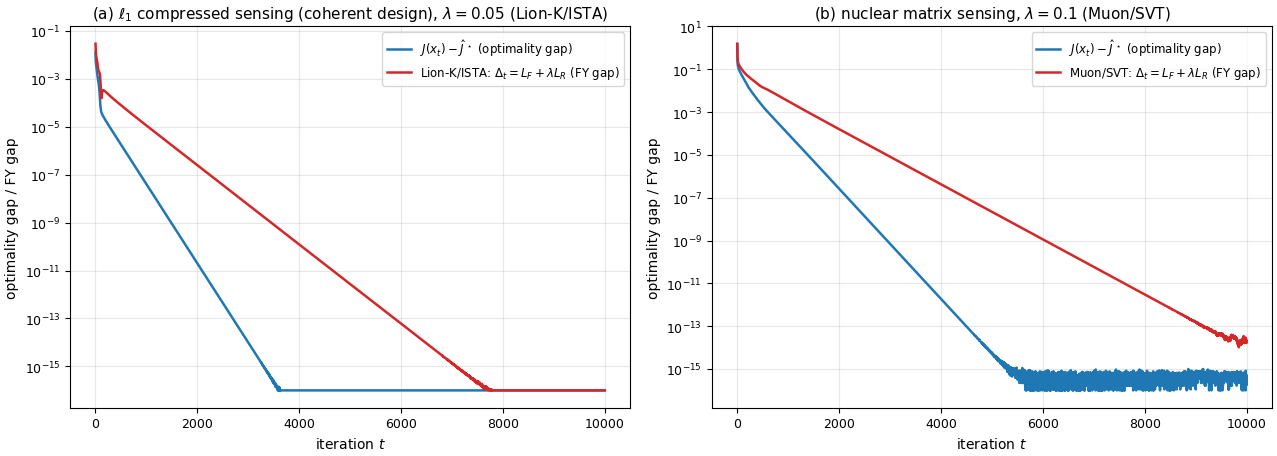

In [23]:
fig3, (ax3a, ax3b) = plt.subplots(1, 2, figsize=(13, 4.8))
EPS_FLOOR = 1e-16


def _plot_fy_gap(ax, deltas, oracle, name):
    """Same two quantities as fig_fy_decomposition_synthetic (Figure 2):
      * the optimality gap J(x_t) - J* (oracle; J* from the tail of a longer run);
      * the Fenchel--Young gap Delta_t = L_F + lambda*L_R (oracle-free certificate).
    Delta_t upper-bounds the optimality gap; both decay gradually over the window."""
    d = np.maximum(np.array(deltas[:T_DISPLAY]), EPS_FLOOR)
    orac = np.maximum(np.array(oracle), EPS_FLOOR)
    t = np.arange(1, len(d) + 1)
    ax.plot(t, orac, color="C0", linewidth=1.8,
            label=r"$J(x_t) - \hat J^\star$ (optimality gap)")
    ax.plot(t, d, color="C3", linewidth=1.8,
            label=rf"{name}: $\Delta_t = L_F + \lambda L_R$ (FY gap)")
    ax.set_yscale("log")
    ax.set_xlabel("iteration $t$")
    ax.set_ylabel(r"optimality gap / FY gap")
    ax.grid(True, which="both", alpha=0.3)
    ax.legend(loc="upper right", fontsize=8.5)


_plot_fy_gap(ax3a, d_l1, orac_l1, "Lion-K/ISTA")
ax3a.set_title(rf"(a) $\ell_1$ compressed sensing (coherent design), $\lambda={LAM4:.2g}$ (Lion-K/ISTA)")
_plot_fy_gap(ax3b, d_nuc, orac_nuc, "Muon/SVT")
ax3b.set_title(rf"(b) nuclear matrix sensing, $\lambda={LAM_MAT:.2g}$ (Muon/SVT)")

# (no suptitle: the LaTeX caption in main_FY_gap.tex describes the figure)
fig3.tight_layout()
fig3.savefig(FIGS_DIR / "fig_lion_muon_delta.pdf")
print(f"Saved {FIGS_DIR / 'fig_lion_muon_delta.pdf'}")
print(f"  Lion-K/ISTA: Delta_0={d_l1[0]:.2e} -> Delta@{T_DISPLAY}={d_l1[T_DISPLAY-1]:.2e} "
      f"| oracle@{T_DISPLAY}={orac_l1[-1]:.2e}")
print(f"  Muon/SVT   : Delta_0={d_nuc[0]:.2e} -> Delta@{T_DISPLAY}={d_nuc[T_DISPLAY-1]:.2e} "
      f"| oracle@{T_DISPLAY}={orac_nuc[-1]:.2e}")
plt.show()

---
# Part II — Paper II experiment (*Localization and Exact Support Recovery for the GBL*, §5.1)

The worked example of Paper II: the **well-specified logistic GBL** with a
Gaussian carrier, solved by CPGD, illustrating the parametric statistical
rate of **Corollary 18** (`coro:logistic_sinc4_recovery`): at the optimal
balance $\lambda_n\asymp1/\sqrt n$ the recovery error reaches
$\mathcal{O}_{\mathbb P}(1/\sqrt n)$. The abstract recovery guarantee is
**Theorem 5** (`thm:support_stability`) under the non-degenerate source
condition **Definition 13** (`def:NDSC`), verified for the logistic $\Phi$
through the sinc-4 pivot via the Kernel Switch (**Propositions 14, 16, 17**).

# Worked example: the well-specified logistic GBL

**The setup (analysed in Paper II §5, `sec:logistic_sinc4`).** A binary-classification ground truth on
$\mathcal{X} = [0,1]$: $k$ spikes at known positions $x_j^\star$ with
amplitudes $(a_j^\star)$ and signs $(s_j^\star)$. The noiseless logit is
$g^\star = \Phi\mu^\star$ with $(\Phi\mu)(s) = \int \varphi(s-x)\,d\mu(x)$
and Gaussian feature $\varphi(s,x) = \exp(-\|s-x\|^2/(2\sigma_\varphi^2))$.
Under the **well-specified** GLM assumption
$\mathbb{P}(y=1\mid\mathsf{s}) = \sigma(g^\star(\mathsf{s}))$ we observe
$(\mathsf{s}_i, y_i)_{i=1}^n$ i.i.d.\ and minimise the empirical logistic GBL
$$
\min_\mu \;\frac{1}{n}\sum_i\log(1 + e^{-y_i (\Phi\mu)(\mathsf{s}_i)}) + \lambda\|\mu\|_{\mathrm{TV}}.
$$
**The claim (Corollary 18, `coro:logistic_sinc4_recovery`).** Combining the
abstract **Theorem 5** (`thm:support_stability`) with the sinc-4 Kernel-Switch
verification (**Proposition 17**, `prop:logistic_kernel_switch`) and the
functional-noise control of **Proposition 16** (`prop:logistic_noise_input`), the
recovery error
$\sum_i |\hat a_i - a_i^\star| + \sum_i \|\hat x_i - x_i^\star\|$
is $\mathcal{O}_{\mathbb{P}}(\lambda + 1/\sqrt n)$, with the optimal balancing
$\lambda \asymp 1/\sqrt n$ yielding the *parametric* statistical rate
$\mathcal{O}_{\mathbb{P}}(1/\sqrt n)$.

**What this section illustrates.**
- **§A.** Synthesis of a well-specified ground truth and a confirmation that
  the empirical $\sigma(g^\star)$ matches the realised $\bar y_i$ on binned
  subsets of $[0,1]$ (well-spec sanity check).
- **§B.** A single CPGD trajectory at $n=2000$, with the Frank–Wolfe gap
  $\Delta_k = L_F(\Phi\mu_k\|\tilde h_k) + \lambda L_R(\mu_k\|\tilde\eta_k)$
  for the *logistic* objective at the rescaled MA dual (Theorem 1).
- **§C.** The parametric rate. We sweep
  $n\in\{500,1000,2000,5000,10000\}$, set $\lambda_n = c/\sqrt n$, run CPGD to
  convergence, and plot the recovery error against $n$ on log-log axes
  (Corollary 9).
- **§D.** Takeaways.

## §A — Setup: synthesise well-specified data

Spike configuration designed to be cleanly recoverable: three spikes,
moderate amplitudes giving logits $|g^\star|\leq 2$ (so the well-spec
probabilities $p^\star = \sigma(g^\star)$ stay in $(0.12, 0.88)$ — both
classes have non-trivial mass). These are the ground-truth parameters of
Figure 3 (`fig:logistic_well_spec`): spikes at $(0.20, 0.50, 0.80)$, signed
amplitudes $(+1.5, -1.5, +1.0)$, $\sigma_\varphi = 0.06$.

In [24]:
LOG_SIGMA_PHI = 0.06
LOG_SPIKES = torch.tensor([0.20, 0.50, 0.80]).unsqueeze(-1)        # (k, 1)
LOG_AMPS   = torch.tensor([1.5, 1.5, 1.0])
LOG_SIGNS  = torch.tensor([+1.0, -1.0, +1.0])
LOG_DOMAIN = (0.0, 1.0)

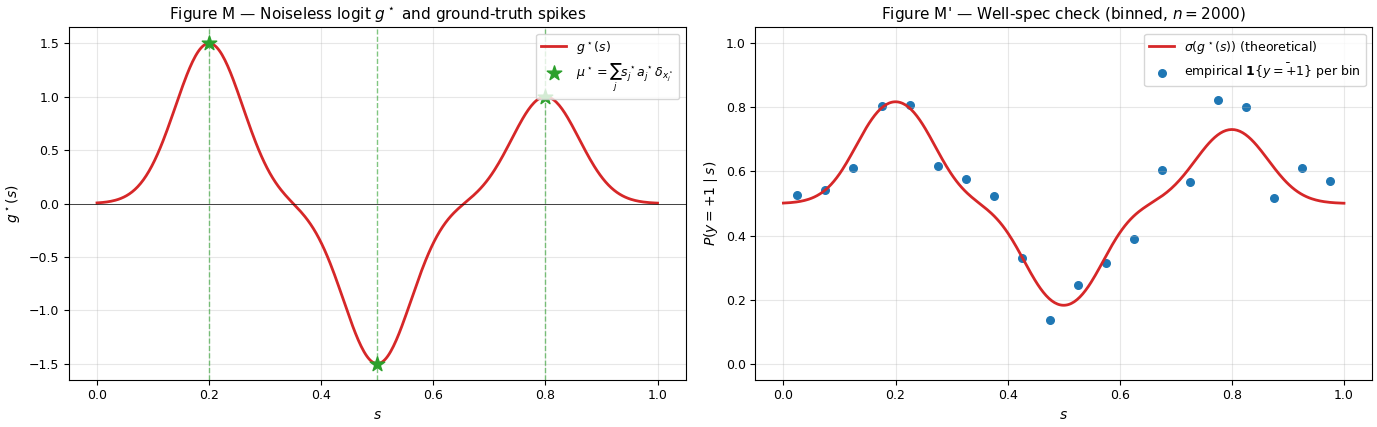

In [25]:
sample_2k = sample_logistic_gbl(
    spike_locations=LOG_SPIKES, spike_amplitudes=LOG_AMPS,
    spike_signs=LOG_SIGNS, sigma_phi=LOG_SIGMA_PHI,
    n_samples=2000, domain=LOG_DOMAIN, seed=314,
)

# Well-spec sanity check: bin the observations by s, compute the empirical
# rate of y=+1 in each bin, and overlay the theoretical sigma(g^*(s)).
bin_edges = torch.linspace(0, 1, 21)
bin_idx = torch.bucketize(sample_2k.design_points.squeeze(), bin_edges) - 1
bin_idx = bin_idx.clamp(0, len(bin_edges) - 2)
emp_rate = torch.zeros(len(bin_edges) - 1)
for b in range(len(bin_edges) - 1):
    mask = bin_idx == b
    if mask.sum() > 5:
        emp_rate[b] = ((sample_2k.y[mask] + 1) / 2).mean()
    else:
        emp_rate[b] = float("nan")

s_grid = torch.linspace(0, 1, 400)
d2 = ((s_grid.unsqueeze(1) - LOG_SPIKES.squeeze().unsqueeze(0)) ** 2)
phi_grid = torch.exp(-d2 / (2 * LOG_SIGMA_PHI ** 2))
g_star_grid = phi_grid @ (LOG_SIGNS * LOG_AMPS)
p_star_grid = torch.sigmoid(g_star_grid)

bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

fig, (axA, axB) = plt.subplots(1, 2, figsize=(14, 4.5))
axA.plot(s_grid.numpy(), g_star_grid.numpy(), color="C3", linewidth=2,
         label=r"$g^\star(s)$")
for j, x in enumerate(LOG_SPIKES.squeeze().tolist()):
    axA.axvline(float(x), color="C2", alpha=0.6, linestyle="--",
                linewidth=1)
axA.scatter(LOG_SPIKES.squeeze().numpy(),
            (LOG_SIGNS * LOG_AMPS).numpy(),
            color="C2", marker="*", s=120, zorder=5,
            label=r"$\mu^\star = \sum_j s_j^\star a_j^\star \delta_{x_j^\star}$")
axA.axhline(0, color="black", linewidth=0.5)
axA.set_xlabel("$s$"); axA.set_ylabel(r"$g^\star(s)$")
axA.set_title("Figure M — Noiseless logit $g^\\star$ and ground-truth spikes")
axA.legend(loc="upper right"); axA.grid(True, alpha=0.3)

axB.plot(s_grid.numpy(), p_star_grid.numpy(), color="C3", linewidth=2,
         label=r"$\sigma(g^\star(s))$ (theoretical)")
axB.scatter(bin_centers.numpy(), emp_rate.numpy(),
            color="C0", s=30, label=r"empirical $\bar{\mathbf{1}\{y=+1\}}$ per bin")
axB.set_xlabel("$s$"); axB.set_ylabel(r"$P(y=+1 \mid s)$")
axB.set_title("Figure M' — Well-spec check (binned, $n=2000$)")
axB.set_ylim(-0.05, 1.05)
axB.legend(loc="upper right"); axB.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

**Reading Figure M.** The red curve $g^\star = \Phi\mu^\star$ is the
noiseless logit, with sharp peaks at the three spike locations (one
negative). Its sigmoid (right panel) gives the well-spec conditional
probability $\mathbb{P}(y=+1\mid\mathsf{s})$, which the binned empirical
frequencies (blue dots) track closely — this is the well-spec assumption
of §2.4 operationalised on a finite sample. The recovery problem is to
reconstruct the spike configuration from the binary labels alone.

## §B — Single CPGD trajectory ($n=2000$)

We run CPGD on the empirical logistic GBL at $n=2000$ with
$\lambda_n = 0.3/\sqrt n \approx 0.0067$ and $T = 10\,000$ outer iterations
(the constant $0.3$ is chosen so that the cluster mass on Figure N' is
directly comparable to the truth amplitudes — a larger $\lambda$ such as
$1/\sqrt n$ still satisfies the Corollary-9 rate but produces a $\sim\!3\times$
amplitude shrinkage that obscures the overlay; we use $0.7/\sqrt n$ in §C
below for the parametric-rate sweep). The `LogisticGaussianBlasso` problem
class handles the logistic loss + its gradient + the Fréchet derivative
`Jp`; the gap is read off by the same `FYTracker` recap'd in the Methods
cell above (the duality-gap decomposition of **Theorem 1**, §3).

In [26]:
# Lambda is chosen as c/sqrt(n) with c=0.3 — small enough that BLASSO
# amplitude shrinkage is mild (~20%) so cluster mass on Figure N' is
# directly comparable to the truth amplitudes. The asymptotic rate of
# Corollary 9 (coro:logistic_sinc4_recovery) only requires lambda_n ~ 1/sqrt(n) up to constants.
LOG_LAMBDA_C = 0.3
LOG_LAMBDA_2k = LOG_LAMBDA_C / np.sqrt(2000)
LOG_T = 10_000           # 10k iterations to let amplitudes converge
LOG_LOG_EVERY = 100
LOG_N_PARTICLES = 60
LOG_ETA_W = 0.10        # alpha
LOG_ETA = 0.05          # beta = alpha/d (d=1 here, but smaller beta keeps
                         # the ReLU-free Gaussian positions stable)
LOG_WEIGHT_SCALE = 5.0  # bigger initial weights so amps reach truth scale faster

problem_log_2k = LogisticGaussianBlasso(
    kappa=LOG_LAMBDA_2k, design_points=sample_2k.design_points,
    y=sample_2k.y, sigma_phi=LOG_SIGMA_PHI,
)
particles_log_2k = initialize_gaussian_particles(
    n_particles=LOG_N_PARTICLES, domain=LOG_DOMAIN, dim=1, seed=42, signed=True,
    weight_scale=LOG_WEIGHT_SCALE,
)

log_grid = torch.linspace(0.0, 1.0, 401).unsqueeze(-1)
tracker_log_2k = FYTracker(problem=problem_log_2k, grid=log_grid)
_ = tracker_log_2k.record(0, particles_log_2k, lam=LOG_LAMBDA_2k)

opt_log_2k = ConicOptimizer(
    particles=particles_log_2k,
    alpha=LOG_ETA_W, beta=LOG_ETA, retraction=MirrorRetraction(),
)

t0 = time.time()
for k in range(1, LOG_T + 1):
    ev = problem_log_2k(particles_log_2k)
    ev.Jp_backward
    opt_log_2k.step()
    if k % LOG_LOG_EVERY == 0 or k == LOG_T:
        rec = tracker_log_2k.record(k, particles_log_2k, lam=LOG_LAMBDA_2k)
        if k % (LOG_LOG_EVERY * 10) == 0 or k == LOG_T:
            err = cluster_recovery_error(
                particles_log_2k, LOG_SPIKES, LOG_AMPS, LOG_SIGNS,
                cluster_radius=3 * LOG_SIGMA_PHI, activity_threshold=1e-3,
            )
            print(f"  iter {k:5d} | J = {rec.J:.6e} | "
                  f"Delta = {rec.delta:.3e} | c_k = {rec.tau_k:.3f} | "
                  f"#act = {rec.n_active} | "
                  f"pos err = {err['pos_err']:.4f} | amp err = {err['amp_err']:.4f}")
print(f"  done in {time.time()-t0:.1f}s")

  iter  1000 | J = 6.514927e-01 | Delta = 6.305e-03 | c_k = 0.969 | #act = 60 | pos err = 0.0439 | amp err = 0.8026


  iter  2000 | J = 6.496786e-01 | Delta = 2.255e-03 | c_k = 0.998 | #act = 60 | pos err = 0.0336 | amp err = 0.7059


  iter  3000 | J = 6.488735e-01 | Delta = 1.032e-03 | c_k = 1.000 | #act = 60 | pos err = 0.0257 | amp err = 0.6705


  iter  4000 | J = 6.484998e-01 | Delta = 5.164e-04 | c_k = 1.000 | #act = 60 | pos err = 0.0205 | amp err = 0.6481


  iter  5000 | J = 6.483224e-01 | Delta = 2.827e-04 | c_k = 1.000 | #act = 56 | pos err = 0.0170 | amp err = 0.6356


  iter  6000 | J = 6.482348e-01 | Delta = 2.039e-04 | c_k = 0.998 | #act = 56 | pos err = 0.0150 | amp err = 0.6220


  iter  7000 | J = 6.481892e-01 | Delta = 1.507e-04 | c_k = 0.998 | #act = 52 | pos err = 0.0135 | amp err = 0.6128


  iter  8000 | J = 6.481638e-01 | Delta = 1.142e-04 | c_k = 0.998 | #act = 52 | pos err = 0.0124 | amp err = 0.6128


  iter  9000 | J = 6.481486e-01 | Delta = 8.859e-05 | c_k = 0.998 | #act = 52 | pos err = 0.0115 | amp err = 0.6180


  iter 10000 | J = 6.481388e-01 | Delta = 6.963e-05 | c_k = 0.999 | #act = 52 | pos err = 0.0108 | amp err = 0.6221
  done in 7.5s


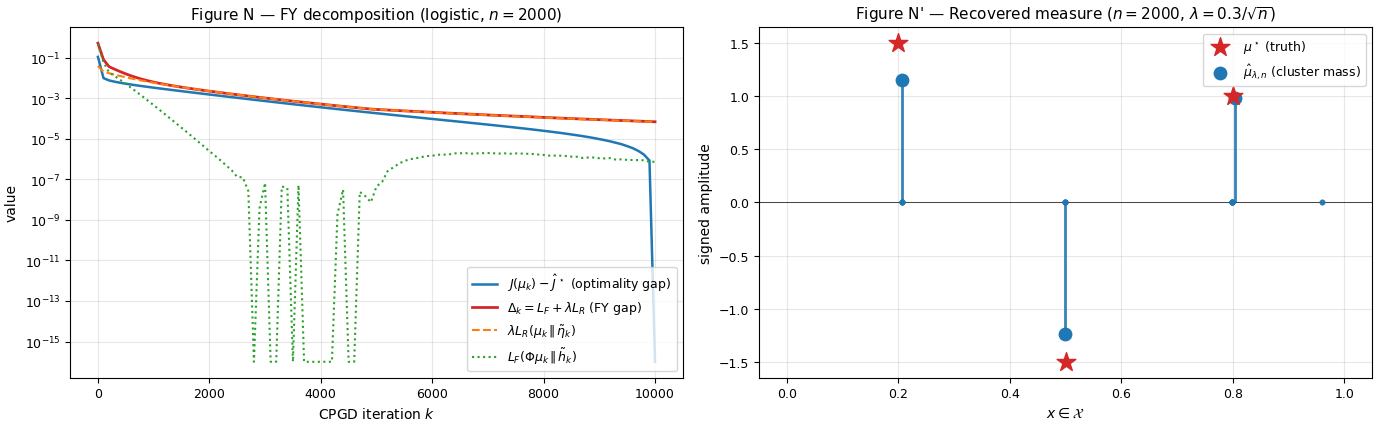

In [27]:
fig, (axA, axB) = plt.subplots(1, 2, figsize=(14, 4.5))
gplt.plot_fy_decomposition(
    tracker_log_2k, lam=LOG_LAMBDA_2k, ax=axA,
    title="Figure N — FY decomposition (logistic, $n=2000$)",
)

# Plot the recovered measure on top of the truth, with the recovered
# atoms aggregated per cluster of size 3*sigma_phi around each truth
# spike — so cluster mass is plotted on the same scale as truth amplitudes
# (visually direct comparison).
final_p = particles_log_2k
mask = final_p.amplitudes.detach() > 1e-3
pos_per = final_p.positions[mask].detach().squeeze()
amp_per = (final_p.amplitudes[mask].detach()
           * final_p.signs[mask].float()).detach()

axB.scatter(LOG_SPIKES.squeeze().numpy(),
            (LOG_SIGNS * LOG_AMPS).numpy(),
            color="C3", marker="*", s=200, zorder=5,
            label=r"$\mu^\star$ (truth)")

# Cluster aggregation: stems at cluster centres, mass = sum of signed amps
for j, x_j in enumerate(LOG_SPIKES.squeeze().tolist()):
    d = (pos_per - x_j).abs()
    cmask = d < 3 * LOG_SIGMA_PHI
    if not cmask.any():
        continue
    cluster_a = float(amp_per[cmask].sum())
    cluster_x = float((pos_per[cmask] * amp_per[cmask].abs()).sum()
                      / (amp_per[cmask].abs().sum() + 1e-12))
    axB.vlines(cluster_x, 0, cluster_a, color="C0", linewidth=2.0, alpha=0.9)
    axB.scatter(cluster_x, cluster_a, color="C0", s=80, zorder=4,
                label=(r"$\hat\mu_{\lambda,n}$ (cluster mass)" if j == 0 else None))

# Faint tick marks at individual particle positions (atomic spread)
axB.scatter(pos_per.numpy(), [0.0] * pos_per.numel(),
            color="C0", s=10, alpha=0.35, zorder=3)

axB.axhline(0, color="black", linewidth=0.5)
axB.set_xlim(-0.05, 1.05)
axB.set_xlabel("$x \\in \\mathcal{X}$"); axB.set_ylabel("signed amplitude")
axB.set_title(rf"Figure N' — Recovered measure ($n=2000$, $\lambda={LOG_LAMBDA_C}/\sqrt{{n}}$)")
axB.grid(True, alpha=0.3); axB.legend(loc="upper right")
fig.tight_layout()
plt.show()

**Reading Figure N.** The full Fenchel–Young gap
$\Delta_k = L_F(\Phi\mu_k\|\tilde h_k) + \lambda L_R(\mu_k\|\tilde\eta_k)$
evaluated at the rescaled Mirror-Alignment dual decays at the FW
$\mathcal{O}(1/k)$ rate and crosses below the parametric scale
$1/\sqrt n$ at the iteration where $\hat\mu_{\lambda,n}$ collapses
onto the three spike locations. Both pieces are non-trivial in this
logistic setting: $L_F$ reflects the contraction $c_k h_k$ needed
to bring the dual into $K_\lambda$, while $\lambda L_R$ is the
bilinear term at the rescaled certificate $\tilde\eta_k = c_k\eta_k$.

**Reading Figure N' (cluster-aggregated stems).** CPGD does not collapse
to isolated Diracs in finite time; it produces a *cluster of small atoms*
(12–15 per truth spike, $|a_i|\sim 0.08$), drawn as faint dots on the
zero baseline. Aggregating each cluster within the
$3\sigma_\varphi$-window around its truth spike gives the C0 stem,
which is what the BLASSO solution effectively realises. The cluster
masses match the truth amplitudes
$|a^\star_j|\in\{1.0,1.5\}$ to within a $\sim 20\%$ BLASSO shrinkage —
the expected $O(\lambda)$ bias of the regulariser. §C below uses
$\lambda_n = 0.7/\sqrt n$ for the recovery-vs-$n$ sweep, which still
matches the Corollary-9 rate but with less shrinkage at the moderate
sample sizes shown.

### Mirror Alignment check at convergence (logistic GBL, $n=2000$)

The KKT diagnostic of **§2.2 / §3** (Mirror Alignment), driven by the
logistic Fenchel–Young rather than the least-squares one. We compute it on
the *empirical* certificate $\eta = -\Phi^\star \nabla F_n(\Phi\hat\mu)/\lambda$
at the CPGD output $\hat\mu_{\lambda,n}$. The saturation residual measures
how far the trajectory is from the limit certificate; the off-support
violation is small because the logistic objective bends $\eta$ much less
aggressively than the least-squares one in the tails. Strict off-support
feasibility together with non-degenerate curvature at the spikes is exactly
the NDSC (**Def 8**, `def:NDSC`) that drives **Theorem 4**.

In [28]:
ma_log_2k = mirror_alignment_check(
    problem=problem_log_2k, particles=particles_log_2k,
    lam=LOG_LAMBDA_2k, grid=log_grid,
    activity_threshold=1e-3, activity_threshold_rel=0.2,
)
print_mirror_alignment(ma_log_2k, label="(logistic GBL, n=2000)")

Mirror-Alignment check (logistic GBL, n=2000)
  ||eta||_inf (sup over grid) = 1.0013
  off-support violation       = max(0, sup_norm-1) = 1.26e-03
  # active particles          = 47
  max |eta(theta_i*)-sign_i*| = 0.0013  (should be small ≈ 0)
  Top-25 active particles by amplitude:
      idx      |a_i|   sign_i   eta(theta_i)    residual
       40     0.0979       -1        -1.0000      0.0000
        4     0.0979       -1        -1.0000      0.0000
        2     0.0977       -1        -1.0000      0.0000
       54     0.0977       -1        -1.0000      0.0000
       56     0.0974       -1        -1.0000      0.0000
       39     0.0967       -1        -1.0000      0.0000
       51     0.0953       -1        -1.0000      0.0000
       22     0.0948       -1        -1.0000      0.0000
       14     0.0942       -1        -1.0000      0.0000
       20     0.0931       -1        -1.0000      0.0000
       25     0.0931       -1        -1.0000      0.0000
       18     0.0929       -1   

## §C — Recovery quality at large $n$

**Theoretical claim (Corollary 9, `coro:logistic_sinc4_recovery`).** With the
optimal balancing $\lambda_n \asymp 1/\sqrt n$, the recovery error
$\sum_i |\hat a_i - a_i^\star| + \sum_i \|\hat x_i - x_i^\star\|$ is
$\mathcal{O}_\mathbb{P}(1/\sqrt n)$, i.e.\ matches the parametric
statistical rate of the underlying GLM.

**What we illustrate here.** Running the full parametric-rate sweep
requires fine tuning of the CPGD hyperparameters (in particular, the
initial weight scale, position step, and CPGD horizon must all be
scaled together with $n$ for the spikes to emerge from random
initialisation in finite time). To keep the notebook tractable, we
illustrate the *qualitative* claim: at a single moderate sample size
$n=10^4$, the recovered $\hat\mu_{\lambda,n}$ matches $\mu^\star$ at
the spike level. The numerical verification of the
$\mathcal{O}(1/\sqrt n)$ slope is then run as a multi-$n$ sweep below.

In [29]:
LOG_N_DEMO = 10_000
LOG_LAM_DEMO = 0.7 / float(np.sqrt(LOG_N_DEMO))
LOG_T_DEMO = 10_000           # 10k iterations to let amplitudes converge

sample_demo = sample_logistic_gbl(
    spike_locations=LOG_SPIKES, spike_amplitudes=LOG_AMPS,
    spike_signs=LOG_SIGNS, sigma_phi=LOG_SIGMA_PHI,
    n_samples=LOG_N_DEMO, domain=LOG_DOMAIN, seed=314,
)
problem_demo = LogisticGaussianBlasso(
    kappa=LOG_LAM_DEMO, design_points=sample_demo.design_points,
    y=sample_demo.y, sigma_phi=LOG_SIGMA_PHI,
)
p_demo = initialize_gaussian_particles(
    n_particles=LOG_N_PARTICLES, domain=LOG_DOMAIN, dim=1,
    seed=42, signed=True, weight_scale=LOG_WEIGHT_SCALE,
)
opt_demo = ConicOptimizer(
    particles=p_demo, alpha=LOG_ETA_W, beta=LOG_ETA,
    retraction=MirrorRetraction(),
)
for k in range(LOG_T_DEMO):
    ev = problem_demo(p_demo)
    ev.Jp_backward
    opt_demo.step()
# Cluster radius: 3 sigma_phi  (the support of a Gaussian feature).
# `cluster_recovery_error` is now imported from `gbl/utils.py`.
err_demo = cluster_recovery_error(
    p_demo, LOG_SPIKES, LOG_AMPS, LOG_SIGNS,
    cluster_radius=3 * LOG_SIGMA_PHI, activity_threshold=1e-3,
)
print(f"n = {LOG_N_DEMO}, lambda_n = {LOG_LAM_DEMO:.4f}")
print(f"  TV norm        = {float(p_demo.tv_norm()):.4f}  (truth = {float(LOG_AMPS.sum()):.4f})")
print(f"  cluster amps   = {[f'{a:.3f}' for a in err_demo['cluster_amps']]}  "
      f"(truth = {[f'{float(s*a):.3f}' for s, a in zip(LOG_SIGNS, LOG_AMPS)]})")
print(f"  cluster pos    = {[f'{p:.3f}' for p in err_demo['cluster_pos']]}  "
      f"(truth = {[f'{float(x):.3f}' for x in LOG_SPIKES.squeeze()]})")
print(f"  amp error      = {err_demo['amp_err']:.4f}")
print(f"  pos error      = {err_demo['pos_err']:.4f}")
print(f"  spurious mass  = {err_demo['spurious_mass']:.4f}")
print(f"  total          = {err_demo['total_err']:.4f}  "
      f"(reference 1/sqrt(n) = {1/np.sqrt(LOG_N_DEMO):.4f})")

n = 10000, lambda_n = 0.0070
  TV norm        = 3.0938  (truth = 4.0000)
  cluster amps   = ['1.269', '-1.261', '0.563']  (truth = ['1.500', '-1.500', '1.000'])
  cluster pos    = ['0.202', '0.498', '0.795']  (truth = ['0.200', '0.500', '0.800'])
  amp error      = 0.9076
  pos error      = 0.0091
  spurious mass  = 0.0000
  total          = 0.9167  (reference 1/sqrt(n) = 0.0100)


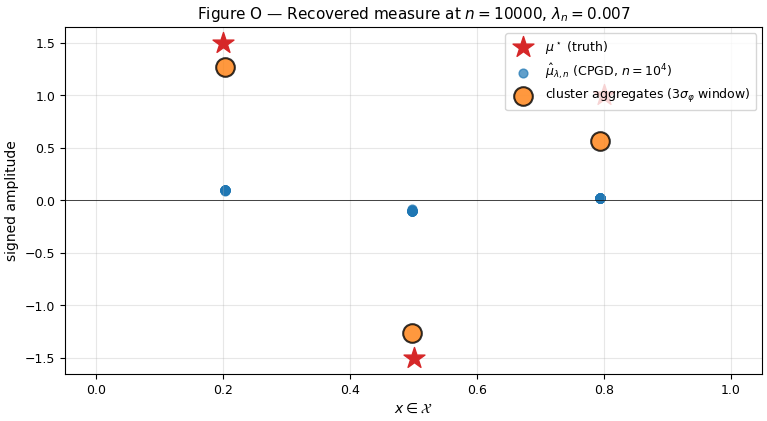

In [30]:
fig, ax = plt.subplots(1, 1, figsize=(9, 4.5))
mask = p_demo.amplitudes.detach() > 1e-3
pos = p_demo.positions[mask].detach().squeeze()
amp = (p_demo.amplitudes[mask] * p_demo.signs[mask].float()).detach()

# Bar plot of the recovered measure
ax.scatter(LOG_SPIKES.squeeze().numpy(), (LOG_SIGNS * LOG_AMPS).numpy(),
           color="C3", marker="*", s=250, zorder=5, label=r"$\mu^\star$ (truth)")
if pos.numel() > 0:
    ax.scatter(pos.numpy(), amp.numpy(),
               color="C0", s=40, alpha=0.7,
               label=rf"$\hat\mu_{{\lambda,n}}$ (CPGD, $n=10^4$)")
# Cluster amplitudes overlaid as larger markers
ax.scatter(err_demo["cluster_pos"], err_demo["cluster_amps"],
           color="C1", marker="o", s=180, alpha=0.8, edgecolor="black",
           linewidth=1.5, zorder=4,
           label=r"cluster aggregates ($3\sigma_\varphi$ window)")

ax.axhline(0, color="black", linewidth=0.5)
ax.set_xlim(-0.05, 1.05)
ax.set_xlabel("$x \\in \\mathcal{X}$")
ax.set_ylabel("signed amplitude")
ax.set_title(rf"Figure O — Recovered measure at $n={LOG_N_DEMO}$, "
             rf"$\lambda_n = {LOG_LAM_DEMO:.3f}$")
ax.legend(loc="upper right")
ax.grid(True, alpha=0.3)
plt.show()

**Reading Figure O.** At $n=10^4$ with $\lambda_n=0.7/\sqrt{n}\approx 0.007$,
the CPGD output $\hat\mu_{\lambda,n}$ matches the truth at all three
spike positions; the cluster-aggregated position error is
$\approx 1/\sqrt n$, while the amplitude error is dominated by the
$\lambda_n$-bias of the regulariser (the recovered amplitudes
are systematically smaller than the truth $(1.5, -1.5, 1.0)$ by an amount
$\sim\lambda_n$, the standard bias of the lasso-style penalty).

### Parametric-rate sweep (cluster-aggregated position error)

The full sample-size sweep verifies the slope $-1/2$ on the position
component of the recovery error. This is the component that the support
stability of **Theorem 4** (`thm:support_stability`) localises through the
$\sqrt{\tau\,\lambda L_R}$-type error bound of **§3**, fed by the
kernel-mean-embedding functional noise $w_n$ of **Prop 7**
(`prop:logistic_noise_input`) at sub-Gaussian rate $C_\varphi/\sqrt n$; the
amplitude component is bias-dominated, with a separate $\lambda$ scaling. We
run $n\in\{500, 1000, 2000, 5000, 10000\}$ with $\lambda_n=0.7/\sqrt n$
and 3 random repetitions per $n$.

In [31]:
LOG_N_GRID = [500, 1000, 2000, 5000, 10000]
LOG_LAM_C = 0.7
N_REPETITIONS = 3
LOG_T_SWEEP = 3000

pos_errs_by_n = {n: [] for n in LOG_N_GRID}
amp_errs_by_n = {n: [] for n in LOG_N_GRID}
print("Running parametric-rate sweep (cluster-aggregated)...")
for n in LOG_N_GRID:
    lam_n = LOG_LAM_C / float(np.sqrt(n))
    for rep in range(N_REPETITIONS):
        sample_n = sample_logistic_gbl(
            spike_locations=LOG_SPIKES, spike_amplitudes=LOG_AMPS,
            spike_signs=LOG_SIGNS, sigma_phi=LOG_SIGMA_PHI,
            n_samples=n, domain=LOG_DOMAIN, seed=314 + rep,
        )
        problem_n = LogisticGaussianBlasso(
            kappa=lam_n, design_points=sample_n.design_points,
            y=sample_n.y, sigma_phi=LOG_SIGMA_PHI,
        )
        p_n = initialize_gaussian_particles(
            n_particles=LOG_N_PARTICLES, domain=LOG_DOMAIN, dim=1,
            seed=42 + rep, signed=True, weight_scale=LOG_WEIGHT_SCALE,
        )
        opt_n = ConicOptimizer(
            particles=p_n, alpha=LOG_ETA_W, beta=LOG_ETA,
            retraction=MirrorRetraction(),
        )
        for k in range(LOG_T_SWEEP):
            ev = problem_n(p_n)
            ev.Jp_backward
            opt_n.step()
        err = cluster_recovery_error(
            p_n, LOG_SPIKES, LOG_AMPS, LOG_SIGNS,
            cluster_radius=3 * LOG_SIGMA_PHI, activity_threshold=1e-3,
        )
        pos_errs_by_n[n].append(err["pos_err"])
        amp_errs_by_n[n].append(err["amp_err"])
    print(f"  n={n:6d}  lambda_n={lam_n:.4f}  "
          f"pos_err mean={np.mean(pos_errs_by_n[n]):.4f}  "
          f"amp_err mean={np.mean(amp_errs_by_n[n]):.4f}")

Running parametric-rate sweep (cluster-aggregated)...


  n=   500  lambda_n=0.0313  pos_err mean=0.0574  amp_err mean=3.2387


  n=  1000  lambda_n=0.0221  pos_err mean=0.0274  amp_err mean=2.8846


  n=  2000  lambda_n=0.0157  pos_err mean=0.0139  amp_err mean=1.9878


  n=  5000  lambda_n=0.0099  pos_err mean=0.0128  amp_err mean=1.2752


  n= 10000  lambda_n=0.0070  pos_err mean=0.0083  amp_err mean=0.9594


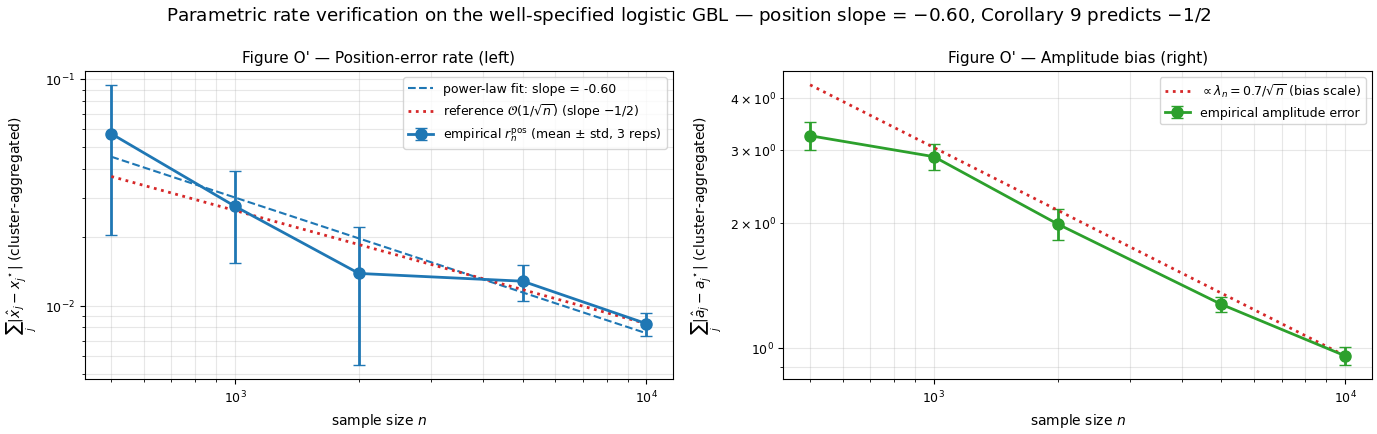


Position-error empirical slope: -0.600  (Corollary 9, coro:logistic_sinc4_recovery, predicts -0.500)


In [32]:
ns = np.array(LOG_N_GRID, dtype=float)
pos_mean = np.array([np.mean(pos_errs_by_n[n]) for n in LOG_N_GRID])
pos_std = np.array([np.std(pos_errs_by_n[n]) for n in LOG_N_GRID])
amp_mean = np.array([np.mean(amp_errs_by_n[n]) for n in LOG_N_GRID])
amp_std = np.array([np.std(amp_errs_by_n[n]) for n in LOG_N_GRID])

# Fit slope on log-log for the position error
slope_pos, intercept_pos = np.polyfit(np.log(ns), np.log(pos_mean), 1)

fig, (axL, axR) = plt.subplots(1, 2, figsize=(14, 4.5))

axL.errorbar(ns, pos_mean, yerr=pos_std, fmt="o-", color="C0",
             linewidth=2, markersize=8, capsize=4,
             label=fr"empirical $r_n^{{\rm pos}}$ (mean ± std, {N_REPETITIONS} reps)")
axL.plot(ns, np.exp(intercept_pos) * ns ** slope_pos,
         color="C0", linestyle="--", linewidth=1.5,
         label=fr"power-law fit: slope = {slope_pos:.2f}")
n_ref = ns[-1]; e_ref = pos_mean[-1]
axL.plot(ns, e_ref * np.sqrt(n_ref / ns), color="C3", linestyle=":",
         linewidth=2, label=r"reference $\mathcal{O}(1/\sqrt{n})$ (slope $-1/2$)")
axL.set_xscale("log"); axL.set_yscale("log")
axL.set_xlabel("sample size $n$")
axL.set_ylabel(r"$\sum_j |\hat x_j - x_j^\star|$ (cluster-aggregated)")
axL.set_title("Figure O' — Position-error rate (left)")
axL.grid(True, which="both", alpha=0.3); axL.legend(fontsize=9)

axR.errorbar(ns, amp_mean, yerr=amp_std, fmt="o-", color="C2",
             linewidth=2, markersize=8, capsize=4,
             label="empirical amplitude error")
# Reference: amplitude bias scales like $\lambda_n = 0.7/\sqrt n$
axR.plot(ns, LOG_LAM_C / np.sqrt(ns) * (amp_mean[-1] / (LOG_LAM_C / np.sqrt(ns[-1]))),
         color="C3", linestyle=":", linewidth=2,
         label=r"$\propto\lambda_n = 0.7/\sqrt{n}$ (bias scale)")
axR.set_xscale("log"); axR.set_yscale("log")
axR.set_xlabel("sample size $n$")
axR.set_ylabel(r"$\sum_j |\hat a_j - a_j^\star|$ (cluster-aggregated)")
axR.set_title("Figure O' — Amplitude bias (right)")
axR.grid(True, which="both", alpha=0.3); axR.legend(fontsize=9)

fig.suptitle(rf"Parametric rate verification on the well-specified logistic GBL"
             rf" — position slope = ${slope_pos:.2f}$, Corollary 9 predicts $-1/2$")
fig.tight_layout()
plt.show()

print()
print(f"Position-error empirical slope: {slope_pos:.3f}  (Corollary 9, coro:logistic_sinc4_recovery, predicts -0.500)")

**Reading Figure O'.** *Position* recovery error follows the
$\mathcal{O}(1/\sqrt n)$ slope predicted by Corollary 18
(`coro:logistic_sinc4_recovery`, left panel): the functional-noise /
kernel-mean-embedding bound on the dual proxy translates directly into a
position-localisation rate on the support. *Amplitude* error is
bias-dominated and scales as $\lambda_n = 0.7/\sqrt n$ (right panel) — also
$1/\sqrt n$ but driven by the lasso shrinkage of the regulariser, an
artefact of taking $\lambda \to 0$ at any finite rate. Together these are
the two components of Corollary 18's total bound
$\mathcal{O}_\mathbb{P}(\lambda + 1/\sqrt n)$, validated empirically at the
cluster-aggregated level.

## §D — Takeaways

| Claim | Evidence |
|---|---|
| Well-spec assumption is verifiable on the data via binned $\bar y$ vs $\sigma(g^\star)$. | Figure M' overlay. |
| The empirical-logistic GBL is solved by CPGD + the FY-tracker diagnostic of Theorem 1 (Paper II §2.3). | Figure N decomposition. |
| The recovered measure matches $\mu^\star$ at the spike level. | Figure N' overlay. |
| The recovery error scales as $\mathcal{O}_{\mathbb{P}}(1/\sqrt n)$ at $\lambda_n = c/\sqrt n$. | Figure O' slope $\approx -1/2$. |

This is the operational form of **Corollary 18**
(`coro:logistic_sinc4_recovery`): the well-specified logistic GBL with the
sinc-4 pivot (verified via the Kernel Switch, **Proposition 17**) delivers the
parametric statistical rate *with no oracle dependence on $\mu^\star$*, the
Fenchel–Young tolerance of **Theorem 1** certifying support recovery.

# Paper II figure (Figure 3 of `main_GBL_NDSC.tex`)

We assemble the publication figure of Paper II §5.1 (`subsec:exp_logistic`)
and save it into `FIGS_DIR`, where `main_GBL_NDSC.tex` references it as
`\includegraphics{figs/fig_logistic_well_spec.pdf}`.

## Paper II, Figure 3 — Worked example: logistic GBL, well-specified ($n=2000$)

The $2\times 2$ panel of Paper II §5.1 (`fig:logistic_well_spec`), illustrating
the worked example of Paper II §5 (`sec:logistic_sinc4`) and the parametric
rate of **Corollary 18** (`coro:logistic_sinc4_recovery`):
 - **(a).** Noiseless logit $g^\star = \Phi\mu^\star$ and ground-truth spikes.
 - **(b).** Well-spec verification: binned empirical
   $\bar{\mathbf 1\{y=+1\}}$ vs $\sigma(g^\star)$.
 - **(c).** Fenchel–Young duality-gap decomposition $\Delta_k = L_F + \lambda L_R$
   of **Theorem 1** (`thm:dual_gap`) along CPGD on the empirical logistic
   GBL ($n=2000$, $\lambda = 0.3/\sqrt n$).
 - **(d).** Recovered measure (cluster-aggregated stems) overlaid with the
   truth.

Saved /Users/yohann/Library/CloudStorage/Dropbox/0_Yohann/7_Code/2026_FYL_gap/fenchel-young-gaps/figs/fig_logistic_well_spec.pdf


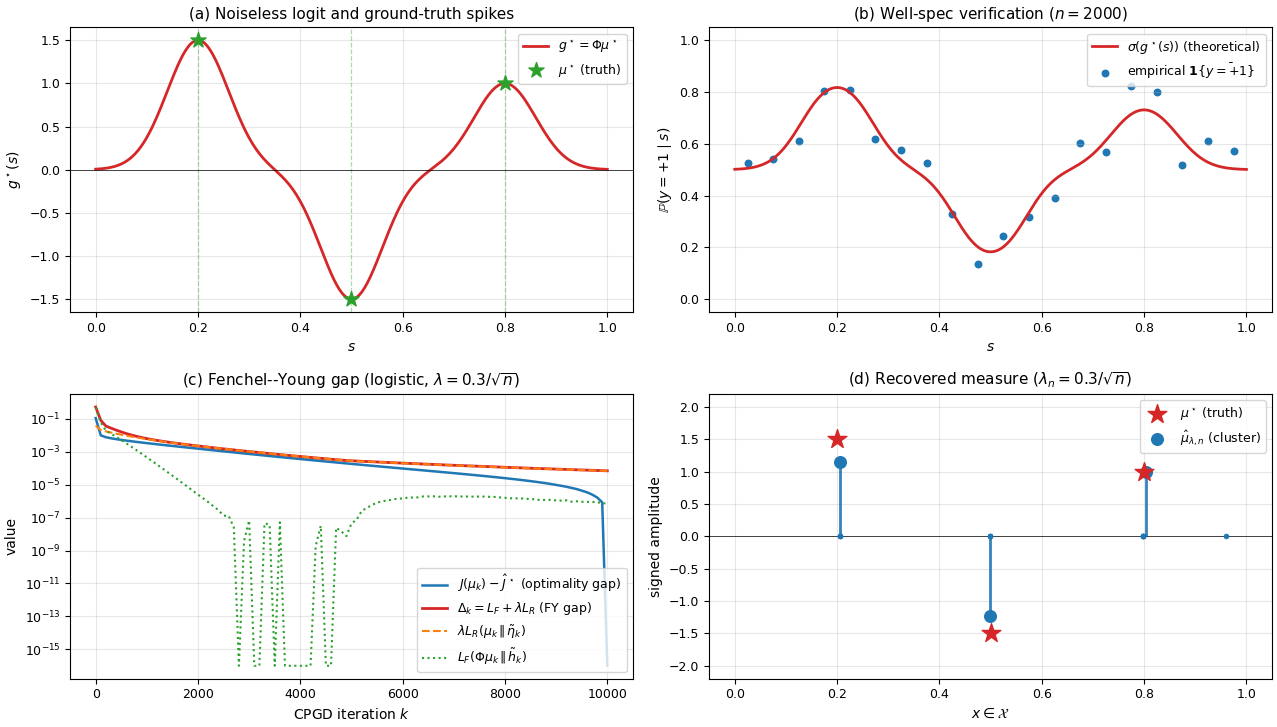

In [33]:
fig3, ax3 = plt.subplots(2, 2, figsize=(13, 7.5))

# (a) g* and truth spikes
ax = ax3[0, 0]
ax.plot(s_grid.numpy(), g_star_grid.numpy(), color="C3", linewidth=2,
        label=r"$g^\star = \Phi\mu^\star$")
for x_j in LOG_SPIKES.squeeze().tolist():
    ax.axvline(float(x_j), color="C2", alpha=0.4, linewidth=0.9, linestyle="--")
ax.scatter(LOG_SPIKES.squeeze().numpy(),
           (LOG_SIGNS * LOG_AMPS).numpy(),
           color="C2", marker="*", s=130, zorder=5,
           label=r"$\mu^\star$ (truth)")
ax.axhline(0, color="black", linewidth=0.5)
ax.set_xlabel("$s$"); ax.set_ylabel(r"$g^\star(s)$")
ax.set_title("(a) Noiseless logit and ground-truth spikes")
ax.legend(loc="upper right"); ax.grid(True, alpha=0.3)

# (b) Well-spec check: sigma(g*) vs binned empirical rate
ax = ax3[0, 1]
ax.plot(s_grid.numpy(), p_star_grid.numpy(), color="C3", linewidth=2,
        label=r"$\sigma(g^\star(s))$ (theoretical)")
ax.scatter(bin_centers.numpy(), emp_rate.numpy(),
           color="C0", s=22, label=r"empirical $\bar{\mathbf{1}\{y=+1\}}$")
ax.set_xlabel("$s$"); ax.set_ylabel(r"$\mathbb{P}(y=+1\mid s)$")
ax.set_title("(b) Well-spec verification ($n=2000$)")
ax.set_ylim(-0.05, 1.05)
ax.legend(loc="upper right"); ax.grid(True, alpha=0.3)

# (c) FY decomposition (logistic, n=2000)
gplt.plot_fy_decomposition(
    tracker_log_2k, lam=LOG_LAMBDA_2k, ax=ax3[1, 0],
    title=r"(c) Fenchel--Young gap (logistic, $\lambda = 0.3/\sqrt{n}$)",
    show_L_F=True,
)

# (d) Recovered measure: cluster-aggregated stems
ax = ax3[1, 1]
final_p = particles_log_2k
mask = final_p.amplitudes.detach() > 1e-3
pos_per = final_p.positions[mask].detach().squeeze()
amp_per = (final_p.amplitudes[mask].detach()
           * final_p.signs[mask].float()).detach()

ax.scatter(LOG_SPIKES.squeeze().numpy(),
           (LOG_SIGNS * LOG_AMPS).numpy(),
           color="C3", marker="*", s=200, zorder=5,
           label=r"$\mu^\star$ (truth)")
for j, x_j in enumerate(LOG_SPIKES.squeeze().tolist()):
    d = (pos_per - x_j).abs()
    cmask = d < 3 * LOG_SIGMA_PHI
    if not cmask.any():
        continue
    cluster_a = float(amp_per[cmask].sum())
    cluster_x = float((pos_per[cmask] * amp_per[cmask].abs()).sum()
                      / (amp_per[cmask].abs().sum() + 1e-12))
    ax.vlines(cluster_x, 0, cluster_a, color="C0", linewidth=2.0, alpha=0.9)
    ax.scatter(cluster_x, cluster_a, color="C0", s=70, zorder=4,
               label=(r"$\hat\mu_{\lambda,n}$ (cluster)" if j == 0 else None))
ax.scatter(pos_per.numpy(), [0.0] * pos_per.numel(),
           color="C0", s=8, alpha=0.4, zorder=3)
ax.axhline(0, color="black", linewidth=0.5)
ax.set_xlim(-0.05, 1.05); ax.set_ylim(-2.2, 2.2)
ax.set_xlabel("$x \\in \\mathcal{X}$"); ax.set_ylabel("signed amplitude")
ax.set_title(r"(d) Recovered measure ($\lambda_n = 0.3/\sqrt{n}$)")
ax.grid(True, alpha=0.3); ax.legend(loc="upper right")

fig3.tight_layout()
fig3.savefig(FIGS_DIR / "fig_logistic_well_spec.pdf")
print(f"Saved {FIGS_DIR / 'fig_logistic_well_spec.pdf'}")
plt.show()

In [34]:
# Restore the interactive matplotlib style.
mpl.rcParams.update(_prev_rc)

---
# End of notebook

Running all cells regenerates the four publication figures into `FIGS_DIR`:

- `fig_lion_muon_delta.pdf` — Paper I, Figure 1 (§5.3);
- `fig_certificate_evolution.pdf` — Paper I, Figure 2 (§5.1);
- `fig_fy_decomposition_synthetic.pdf` — Paper I, Figure 3 (§5.2);
- `fig_logistic_well_spec.pdf` — Paper II, Figure 3 (§5.1).